# Лабораторная работа 1 — рабочий ноутбук

**ФИО: Бондарев Виктор Александрович**

**Файлы данных: S02**

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "data/clients.csv"
RAW_TXN = "data/transactions.csv"

DATA_START = pd.Timestamp("2024-01-01")
DATA_END = pd.Timestamp("2025-06-30")
BASE_MONTHS = pd.period_range("2024-01", "2024-12", freq="M")
EVAL_MONTHS = pd.period_range("2025-01", "2025-06", freq="M")
ALL_MONTHS = BASE_MONTHS.append(EVAL_MONTHS)

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
df_clients_raw = pd.read_csv(RAW_CLIENTS)
df_txn_raw = pd.read_csv(RAW_TXN, sep=";", decimal=",", encoding="cp1251")

display(df_clients_raw.head())
display(df_txn_raw.head())

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004413,1970-10-31,М,г. Санкт-Петербург,Массовый,Золото,Дебетовая,29.06.2015,11.04.2020,Зарплата в другом банке,98700.0,Да,2024-06,NaN,151,Да
1,C004793,1978-01-02,М,казань,Массовый,Базовый,Дебетовая,20.03.2017,31.03.2020,Зарплата в нашем банке,-999.0,Да,2024-09,NaN,459,Да
2,C000766,1985-12-16,Ж,Нижний Новгород,Массовый,Базовый,Кредитная,08.02.2021,25.05.2021,Зарплата в другом банке,73900.0,Да,2024-08,NaN,149,Да
3,C005506,1980-04-23,М,Москва,Зарплатный,Серебро,Кредитная,17.03.2016,31.01.2022,Зарплата в нашем банке,94000.0,Да,2025-01,NaN,601,Да
4,C003390,1993-03-25,Ж,Москва,Массовый,Базовый,Дебетовая,10.11.2016,21.02.2020,Зарплата в другом банке,19700.0,Да,2024-05,NaN,392,Да


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990218,C001808,2023-12-05 15:32:29,273.24,RUB,Транспорт,4111,Карта,успешно
1,990055,C000890,2023-12-08 12:57:12,2184.78,RUB,Связь и интернет,4814,Карта,успешно
2,990199,C002011,2023-12-11 13:15:30,820.11,RUB,Кафе и рестораны,5812,Токен,успешно
3,990051,C003480,2023-12-15 17:42:28,629.01,RUB,Кафе и рестораны,5812,Токен,успешно
4,990026,C000525,2023-12-16,268.26,RUB,Развлечения и досуг,7832,Онлайн-банк,успешно


In [3]:
df_clients_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5728 entries, 0 to 5727
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   client_id           5728 non-null   object 
 1   birth_date          5728 non-null   object 
 2   gender              5728 non-null   object 
 3   city                5728 non-null   object 
 4   segment             5728 non-null   object 
 5   loyalty_tier        5728 non-null   object 
 6   card_type           5728 non-null   object 
 7   registration_date   5728 non-null   object 
 8   card_open_date      5728 non-null   object 
 9   income_source       5728 non-null   object 
 10  monthly_income      5198 non-null   float64
 11  has_mobile_app      5728 non-null   object 
 12  app_last_login      3527 non-null   object 
 13  satisfaction_score  2264 non-null   float64
 14  branch_code         5728 non-null   int64  
 15  marketing_opt_in    5728 non-null   object 
dtypes: flo

In [4]:
df_txn_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 627703 entries, 0 to 627702
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   txn_id        627703 non-null  int64  
 1   client_id     627703 non-null  object 
 2   txn_datetime  627703 non-null  object 
 3   amount        627703 non-null  float64
 4   currency      627703 non-null  object 
 5   category      627703 non-null  object 
 6   mcc_code      627703 non-null  int64  
 7   channel       627703 non-null  object 
 8   status        627703 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 43.1+ MB


In [5]:
df_clients = df_clients_raw.copy()
df_txn = df_txn_raw.copy()

## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [6]:
def profile(df, name):
    out = pd.DataFrame({
        "n_unique": df.nunique(dropna=True),
        "n_missing": df.isna().sum(),
        "missing_share": (df.isna().mean() * 100).round(1),
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
    print(f"{name}: {len(df):,} строк × {df.shape[1]} колонок".replace(",", " "))
    return out

display(profile(df_clients, "clients"))
display(profile(df_txn, "transactions"))

print("Единица наблюдения: clients - один клиент (ключ client_id); transactions - одна операция (ключ txn_id)")

clients: 5 728 строк × 16 колонок


,n_unique,n_missing,missing_share,example
client_id,5673,0,0.0,C004413
birth_date,4841,0,0.0,1970-10-31
gender,2,0,0.0,М
city,17,0,0.0,г. Санкт-Петербург
segment,4,0,0.0,Массовый
loyalty_tier,4,0,0.0,Золото
card_type,3,0,0.0,Дебетовая
registration_date,3225,0,0.0,29.06.2015
card_open_date,2634,0,0.0,11.04.2020
income_source,3,0,0.0,Зарплата в другом банке


transactions: 627 703 строк × 9 колонок


,n_unique,n_missing,missing_share,example
txn_id,626203,0,0.0,990218
client_id,5987,0,0.0,C001808
txn_datetime,570287,0,0.0,2023-12-05 15:32:29
amount,325587,0,0.0,273.24
currency,3,0,0.0,RUB
category,12,0,0.0,Транспорт
mcc_code,9,0,0.0,4111
channel,4,0,0.0,Карта
status,3,0,0.0,успешно


Единица наблюдения: clients - один клиент (ключ client_id); transactions - одна операция (ключ txn_id)


### 2.2. Дубли

In [7]:
print("client_id в справочнике: уникальных", df_clients.client_id.nunique(), "из", len(df_clients), "строк")
print("txn_id в операциях:      уникальных", df_txn.txn_id.nunique(), "из", len(df_txn), "строк")

client_id в справочнике: уникальных 5673 из 5728 строк
txn_id в операциях:      уникальных 626203 из 627703 строк


In [8]:
# клиенты
cl_full_dup = df_clients.duplicated(keep="first")
cl_id_dup = df_clients.client_id.duplicated(keep=False)
cl_conflict_ids = (df_clients[cl_id_dup & ~df_clients.duplicated(keep=False)].client_id.unique())

print("Клиенты: полных дублей строк      :", cl_full_dup.sum())
print("Клиенты: client_id с конфликтом   :", len(cl_conflict_ids), "-- разные строки с одним id")

Клиенты: полных дублей строк      : 42
Клиенты: client_id с конфликтом   : 13 -- разные строки с одним id


In [9]:
conflict_rows = (df_clients[df_clients.client_id.isin(cl_conflict_ids)].sort_values("client_id"))
display(conflict_rows.head(4))

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
4267,C000283,1985-06-05,Ж,МОСКВА,Премиальный,Серебро,Дебетовая,31.05.2024,25.04.2025,Не указан,314200.0,Да,2025-03,NaN,715,Да
2574,C000283,1985-06-05,Ж,Екатеринбург,Массовый,Серебро,Дебетовая,31.05.2024,25.04.2025,Не указан,314200.0,Да,2025-03,NaN,715,Да
1796,C000368,1965-04-08,М,Екатеринбург,Зарплатный,Базовый,Премиальная,25.11.2017,25.09.2020,Не указан,78600.0,Да,2025-06,4.0,676,Да
1953,C000368,1965-04-08,М,г. Новосибирск,Массовый,Базовый,Премиальная,25.11.2017,25.09.2020,Не указан,78600.0,Да,2025-06,4.0,676,Да


In [10]:
diff_fields = (df_clients[df_clients.client_id.isin(cl_conflict_ids)]
               .groupby("client_id").nunique(dropna=False).gt(1).sum())
print("Поля, по которым расходятся конфликтные записи:", diff_fields[diff_fields > 0].to_dict())

Поля, по которым расходятся конфликтные записи: {'city': 12, 'segment': 8}


#### Клиенты те же, строки отличаются только городом и сегментом.
#### В дальнейшем нужно их оставить, но city, cegment -> NaN.

In [11]:
# операции
tx_full_dup = df_txn.duplicated(keep="first")
tx_id_dup = df_txn.txn_id.duplicated(keep="first")
print("\nОперации: полных дублей строк:", tx_full_dup.sum())
print("Операции: повторов txn_id (всего):", tx_id_dup.sum())

rest = df_txn[~tx_full_dup]
rest_dup = rest[rest.txn_id.duplicated(keep=False)]
print("\nОперации: повторы txn_id не считая полных копий:", rest.txn_id.duplicated().sum())

print(rest_dup.sort_values("txn_id").head(4))

# смотрим чем различаются
other_cols = [c for c in df_txn.columns if c != "txn_datetime"]
only_time_diff = (rest_dup.groupby("txn_id")[other_cols].nunique(dropna=False).max(axis=1) <= 1)

n_only_time = only_time_diff.sum()
n_total = len(only_time_diff)

print(f"\nКоличество txn_id, где отличается только txn_datetime: {n_only_time} из {n_total}")


Операции: полных дублей строк: 1256
Операции: повторов txn_id (всего): 1500

Операции: повторы txn_id не считая полных копий: 244
      txn_id client_id         txn_datetime   amount currency             category  mcc_code      channel   status
2488  102476   C001646  2024-01-04 14:42:52  1196.29      RUB               Аптеки      5912  Онлайн-банк  успешно
2489  102476   C001646           2024-01-04  1196.29      RUB               Аптеки      5912  Онлайн-банк  успешно
4402  104387   C003095           2024-01-06  1267.09      RUB  Развлечения и досуг      7832  Онлайн-банк  успешно
4403  104387   C003095  2024-01-06 09:58:08  1267.09      RUB  Развлечения и досуг      7832  Онлайн-банк  успешно

Количество txn_id, где отличается только txn_datetime: 244 из 244


#### Операции с одинаковым id различаются только форматом txn_datetime, на обработке будет исправлено

### 2.3. Соответствие данных описанию полей из задания

In [12]:
amt = pd.to_numeric(df_txn.amount.astype(str).str.replace(",", ".", regex=False),errors="coerce")
ts = pd.to_datetime(df_txn.txn_datetime, format="ISO8601", errors="coerce")
inc = pd.to_numeric(df_clients.monthly_income, errors="coerce")

CATEGORIES_DECLARED = 9
checks = []

def chk(field, declared, fact, n, d):
    checks.append(dict(field=field, declared=declared, fact=fact, n=n, denominator=d, share=f"{n / d:.2%}"))

n_tx, n_cl = len(df_txn), len(df_clients)
chk("txn_datetime", "дата и время операции", "в части строк только дата (нет времени)",
    int((df_txn.txn_datetime.str.len() == 10).sum()), n_tx)
chk("txn_datetime", "период 2024-01-01 .. 2025-06-30", "есть операции вне периода (2023-12 и 2025-07..2026-08)",
    int(((ts < DATA_START) | (ts >= DATA_END + pd.Timedelta(days=1))).sum()), n_tx)
chk("category", f"одна из {CATEGORIES_DECLARED} категорий",
    f"{df_txn.category.nunique()} написаний",
    int(df_txn.category.isin(["Связь и Интернет", "кафе и рестораны", "Кафе/рестораны"]).sum()), n_tx)

# mcc_code проверяем по доминирующей паре
cat_norm_tmp = df_txn.category.replace({"Связь и Интернет": "Связь и интернет",
                                         "кафе и рестораны": "Кафе и рестораны",
                                         "Кафе/рестораны": "Кафе и рестораны"})
dominant_mcc = df_txn.groupby(cat_norm_tmp)["mcc_code"].agg(lambda s: s.mode()[0])
mcc_bad = (cat_norm_tmp.map(dominant_mcc) != df_txn.mcc_code)
chk("mcc_code", "соответствует категории", "не совпадает с категорией", int(mcc_bad.sum()), n_tx)

chk("amount", "сумма операции (в рублях?)", "валюты RUB/EUR/USD: суммы в EUR/USD в валюте операции",
    int((df_txn.currency != "RUB").sum()), n_tx)

chk("amount", "сумма операции", "отрицательные суммы (все - статус «возврат»)", int((amt < 0).sum()), n_tx)

chk("status", "успешно / отклонено / возврат", "отклонённые операции содержат положительную сумму (деньги не списаны)",
    int((df_txn.status == "отклонено").sum()), n_tx)

chk("client_id (transactions)", "клиент из справочника", "клиента нет в справочнике действующих",
    int((~df_txn.client_id.isin(df_clients.client_id)).sum()), n_tx)

chk("monthly_income", "рублей в месяц", "значение −999",
    int((inc == -999).sum()), n_cl)

chk("monthly_income", "рублей в месяц", "значения 0–1000 (похоже на тысячи рублей)",
    int(((inc > 0) & (inc < 1000)).sum()), n_cl)

chk("city", "город проживания", f"{df_clients.city.nunique()} написаний на 6 городов",
    int((~df_clients.city.isin(["Москва", "Казань", "Санкт-Петербург", "Новосибирск", "Нижний Новгород", "Екатеринбург"])).sum()), n_cl)

chk("satisfaction_score", "оценка по опросу 1–5", "значение отсутствует (опрос прошёл не все)",
    int(df_clients.satisfaction_score.isna().sum()), n_cl)

chk("has_mobile_app / app_last_login", "месяц последнего входа", "вход указан у всех с приложением и ни у кого без (согласовано)",
    int(((df_clients.has_mobile_app == "Нет") & df_clients.app_last_login.notna()).sum()
        + ((df_clients.has_mobile_app == "Да") & df_clients.app_last_login.isna()).sum()), n_cl)

audit_desc = pd.DataFrame(checks)
display(audit_desc)

,field,declared,fact,n,denominator,share
0,txn_datetime,дата и время операции,в части строк только дата (нет времени),50447,627703,8.04%
1,txn_datetime,период 2024-01-01 .. 2025-06-30,есть операции вне периода (2023-12 и 2025-07.....,81,627703,0.01%
2,category,одна из 9 категорий,12 написаний,52096,627703,8.30%
3,mcc_code,соответствует категории,не совпадает с категорией,1616,627703,0.26%
4,amount,сумма операции (в рублях?),валюты RUB/EUR/USD: суммы в EUR/USD в валюте о...,2602,627703,0.41%
5,amount,сумма операции,отрицательные суммы (все - статус «возврат»),7602,627703,1.21%
6,status,успешно / отклонено / возврат,отклонённые операции содержат положительную су...,12373,627703,1.97%
7,client_id (transactions),клиент из справочника,клиента нет в справочнике действующих,27404,627703,4.37%
8,monthly_income,рублей в месяц,значение −999,51,5728,0.89%
9,monthly_income,рублей в месяц,значения 0–1000 (похоже на тысячи рублей),169,5728,2.95%


### 2.4. Связь между таблицами

Операций клиентов, которых нет в справочнике: 27404 (4.37%)
Таких клиентов: 327 | клиентов справочника без единой операции: 13


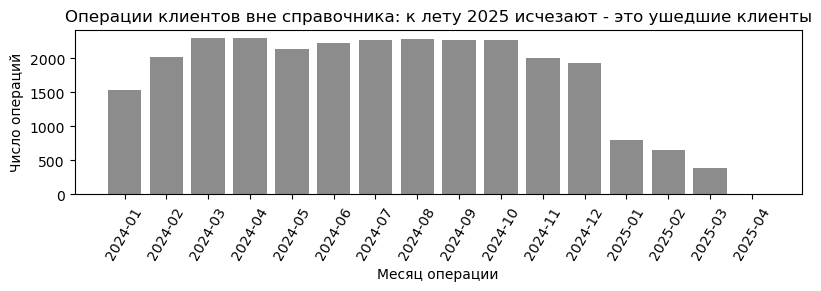

Операции раньше даты регистрации клиента: 0 | раньше открытия текущей карты: 3
Клиентов с картой, открытой в 2024–2025 (нет полного базового года): 772 из 5673


In [13]:
ref_ids = set(df_clients.client_id)
orph_mask = ~df_txn.client_id.isin(ref_ids)
orph_clients = df_txn.loc[orph_mask, "client_id"].nunique()

orph_count = int(orph_mask.sum())
orph_pct = orph_count / len(df_txn) * 100

print(f"Операций клиентов, которых нет в справочнике: {orph_count} ({orph_pct:.2f}%)")
print("Таких клиентов:", orph_clients, "| клиентов справочника без единой операции:",
      len(ref_ids - set(df_txn.client_id)))

# Когда пропадают клиенты вне справочника
orph_m = (pd.to_datetime(df_txn.loc[orph_mask, "txn_datetime"], format="ISO8601").dt.to_period("M")
          .value_counts().sort_index())
orph_m = orph_m[(orph_m.index >= pd.Period("2024-01")) & (orph_m.index <= pd.Period("2025-06"))]
fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
ax.bar(orph_m.index.astype(str), orph_m.values, color="#8C8C8C")
ax.set_title("Операции клиентов вне справочника: к лету 2025 исчезают - это ушедшие клиенты")
ax.set_xlabel("Месяц операции"); ax.set_ylabel("Число операций")
ax.tick_params(axis="x", rotation=60)
plt.show()

# Операции до даты прихода клиента в банк / до открытия текущей карты
cmerge = df_clients.drop_duplicates("client_id").assign(
    reg=lambda d: pd.to_datetime(d.registration_date, format="%d.%m.%Y"),
    cod=lambda d: pd.to_datetime(d.card_open_date, format="%d.%m.%Y"))
m = df_txn.assign(ts=ts).merge(cmerge[["client_id", "reg", "cod"]], on="client_id")
print("Операции раньше даты регистрации клиента:", (m.ts < m.reg).sum(),
      "| раньше открытия текущей карты:", (m.ts.dt.normalize() < m.cod).sum())
print("Клиентов с картой, открытой в 2024–2025 (нет полного базового года):",
      int((cmerge.cod >= "2024-01-01").sum()), "из", len(cmerge))

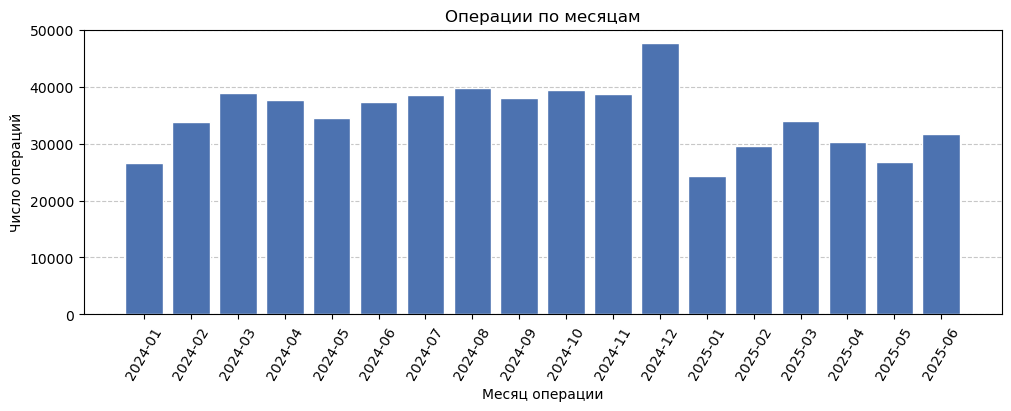

Операций в декабре: 47646
Операций в январе:  24323
Падение: 23323 операций (49.0%)


In [14]:
# смотрим на сезонность
all_m = (pd.to_datetime(df_txn["txn_datetime"], format="ISO8601").dt.to_period("M")
         .value_counts().sort_index())
all_m = all_m[(all_m.index >= pd.Period("2024-01")) & (all_m.index <= pd.Period("2025-06"))]


fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.bar(all_m.index.astype(str), all_m.values, color="#4C72B0", edgecolor="white")
ax.set_title("Операции по месяцам")
ax.set_xlabel("Месяц операции"); ax.set_ylabel("Число операций")
ax.tick_params(axis="x", rotation=60)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True) 
plt.show()


dec_period = pd.Period("2024-12")
jan_period = pd.Period("2025-01")

dec_count = all_m.get(dec_period, 0)
jan_count = all_m.get(jan_period, 0)

drop_abs = dec_count - jan_count
drop_pct = (drop_abs / dec_count) * 100
    
print(f"Операций в декабре: {dec_count}")
print(f"Операций в январе:  {jan_count}")
print(f"Падение: {drop_abs} операций ({drop_pct:.1f}%)")

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.


| # | Что найдено | Сколько | Мешает ли задаче |
|---|---|---|---|
| 1 | Полные дубли строк в `transactions` (+ повтор `txn_id` с разной точностью времени) | 1 256 + 244| завышает число операций - искажает метрику активности |
| 2 | Дубли и конфликты `client_id` в `clients` | 42 + 13 id | клиенты не дают информации по городу и сегменту|
| 4 | Операции вне периода (`2023-12`, `2025-07…2026-08`, `txn_id` вида 99xxxx) | 81 | нарушают окна базового/оцениваемого периодов |
| 5 | Клиенты в операциях, которых нет в справочнике (ушли) | 327 клиент, 27404 операции| кампания им невозможна |
| 6 | 12 написаний на 9 категорий; 17 написаний на 6 городов | 52096 операций / 1678 клиента | ломает группировки |
| 7 | `mcc_code` не соответствует `category` | 1616 операций  | `mcc` ненадёжен; по суммам верна `category` |
| 8 | `monthly_income`: −999, значения в тыс. руб., пропуски | 51 / 169 / 530 строк | искажает доход |
| 9 | Валюты EUR/USD | 2602	 операции  | суммы несопоставимы с рублями|
| 10 | Карта открыта в 2024–2025 | 772 клиентов | у них нет полного базового года - активность растёт искусственно |
| 11 | Сезонность: пик декабря 2024, минимум января | −49% операций в январе | базу "12 мес. против 6 мес." нужно корректировать на сезон |

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [15]:
# журнал
LOG_COLUMNS = ["field", "issue", "scope", "n_rows", "value_before",
               "action", "value_after", "rationale"]
log_rows = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append(dict(field=field, issue=issue, scope=scope, n_rows=int(n_rows),
                         value_before=value_before, action=action,
                         value_after=value_after, rationale=rationale))

### 3.1. Типы, даты, числа

In [16]:
# clients: типы
clients = df_clients.copy()
clients["birth_date"] = pd.to_datetime(clients.birth_date, format="%Y-%m-%d")
clients["registration_date"] = pd.to_datetime(clients.registration_date, format="%d.%m.%Y")
clients["card_open_date"] = pd.to_datetime(clients.card_open_date, format="%d.%m.%Y")
clients["app_last_login"] = pd.to_datetime(clients.app_last_login, format="%Y-%m")
clients["monthly_income"] = pd.to_numeric(clients.monthly_income.astype(str).str.replace(",", ".", regex=False),errors="coerce")
clients["satisfaction_score"] = pd.to_numeric(clients.satisfaction_score).astype("Int8")  # порядковая шкала 1..5
clients["has_mobile_app"] = clients.has_mobile_app.map({"Да": True, "Нет": False})
clients["marketing_opt_in"] = clients.marketing_opt_in.map({"Да": True, "Нет": False})
# branch_code — это код, а не число: оставляем строкой
assert clients.has_mobile_app.notna().all() and clients.marketing_opt_in.notna().all()

# transactions: типы
txn = df_txn.copy()
txn["amount"] = pd.to_numeric(txn.amount, errors="coerce") # '5750,91' -> 5750.91
txn["has_time"] = txn.txn_datetime.astype(str).str.len() > 10 # есть ли время в записи
txn["txn_datetime"] = pd.to_datetime(txn.txn_datetime, format="ISO8601") # даты вида 'ГГГГ-ММ-ДД' и 'ГГГГ-ММ-ДД чч:мм:сс'
txn["txn_id"] = txn.txn_id.astype("int64")

add_log("файлы (оба)", "разные кодировка/разделитель/десятичный знак", "все строки обоих файлов",
        len(df_clients) + len(df_txn), "clients: utf-8, ','; transactions: cp1251, ';', сумма '5750,91'",
        "исправлено", "единые типы: float для сумм, datetime для дат",
        "иначе суммы остаются строками, а кириллица — мусором; определено автоматически по содержимому файлов")
add_log("txn_datetime", "время отсутствует в части записей (только дата)", "has_time == False",
        int((~txn.has_time).sum()), "«2024-01-03»", "оставлено", "datetime 00:00:00 + флаг has_time",
        "метрика считается по месяцам, время не нужно; флаг сохранён для различения копий одного txn_id")
txn.dtypes.to_frame("dtype").T

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status,has_time
dtype,int64,object,datetime64[ns],float64,object,object,int64,object,object,bool


In [17]:
# конфликтные id (одинаковый id, но разные city/segment)
cl_conflict = clients.client_id[clients.client_id.duplicated(keep=False) & ~clients.duplicated(keep=False)].unique()
conflict_ids = set(cl_conflict)
mask_conflict = clients.client_id.isin(conflict_ids)
clients.loc[mask_conflict, ["city", "segment"]] = np.nan
add_log("city, segment","один id, две разные записи (разные city и/или segment)",f"{len(conflict_ids)} id",
        int(mask_conflict.sum()),"C000020: Санкт-Петербург/Массовый и Екатеринбург/Премиальный", "Замена на NaN",
        "city=None, segment=None (обе строки сохранены)",
        "Верную запись установить нельзя. Зануление исключает эти атрибуты из агрегатов, но сохраняет историю операций клиента без искажений.")

# дубли в clients
n0 = len(clients)
clients = clients.drop_duplicates(keep="first")
n_cl_full = n0 - len(clients)
add_log("client_id", "полные дубли строки в справочнике", "строки, повторяющие другую целиком",
        n_cl_full, "2 одинаковые строки на клиента", "удалено", "1 строка на клиента",
        "точная копия не несёт информации; остаётся одна запись, ключ становится уникальным")

# дубли в transactions
n0 = len(txn)
txn = txn.drop_duplicates(keep="first")
n_tx_full = n0 - len(txn)
add_log("txn_id", "полные дубли операций (все поля совпадают)", "повтор строки целиком", n_tx_full,
        "2 одинаковые строки", "удалено", "1 строка на операцию",
        "повторная передача записи из источника; иначе операция считается дважды и завышает активность клиента")

n0 = len(txn)
# среди пар с одним txn_id оставляем версию, где время известно (has_time=True)
txn = (txn.sort_values(["txn_id", "has_time"], ascending=[True, False])
          .drop_duplicates("txn_id", keep="first").reset_index(drop=True))
n_tx_id = n0 - len(txn)
add_log("txn_id", "тот же txn_id, различие только в точности времени (дата без времени vs с временем)",
        "пары с одинаковыми остальными полями", n_tx_id, "«2024-01-01» и «2024-01-01 11:05:30»",
        "удалено", "оставлена запись со временем",
        "это одна операция, записанная дважды; версия со временем информативнее")
assert txn.txn_id.is_unique
print("операции после удаления дублей:", len(txn))

операции после удаления дублей: 626203


### 3.2. Категориальные признаки

In [18]:
is_conflict = clients.client_id.isin(conflict_ids)

CITY_MAP = {"москва": "Москва", "казань": "Казань", "санкт-петербург": "Санкт-Петербург",
            "санкт петербург": "Санкт-Петербург", "спб": "Санкт-Петербург",
            "новосибирск": "Новосибирск", "нижний новгород": "Нижний Новгород",
            "н. новгород": "Нижний Новгород", "екатеринбург": "Екатеринбург"}

def norm_city(s):
    """регистр -> нижний, убираем пробелы по краям и префикс 'г.', затем словарь"""
    key = (s.str.strip().str.lower().str.replace(r"^г\.\s*", "", regex=True))
    return key.map(CITY_MAP)

city_new = norm_city(clients.city)
unrecognized = clients[city_new.isna() & ~is_conflict]

assert unrecognized.empty, f"Не удалось распознать города у обычных клиентов: {unrecognized.city.unique()}"

n_changed = int((city_new.notna() & (city_new != clients.city)).sum())
n_nan = int(city_new.isna().sum())

add_log("city", "разнобой написания города (регистр, «г.», пробелы, «СПб», «Н. Новгород»)", "все строки справочника", n_changed, 
        f"{clients.city.nunique()} написаний, напр. «г. Москва», « москва», «СПб»", "нормализация",
        f"{city_new.nunique()} городов (+ {n_nan} NaN для конфликтных id)", 
        f"сверено со списком из 6 городов; {n_nan} пропусков оставлены намеренно из-за конфликта client_id")

clients["city"] = city_new

In [19]:
# category
CAT_MAP = {"Связь и Интернет": "Связь и интернет", "кафе и рестораны": "Кафе и рестораны",
           "Кафе/рестораны": "Кафе и рестораны"}
n_cat = int(txn.category.isin(CAT_MAP).sum())
add_log("category", "разнобой написания категории (регистр, «/» вместо «и»)", "category in {«Связь и Интернет», «кафе и рестораны», «Кафе/рестораны»}",
        n_cat, f"{txn.category.nunique()} написаний", "нормализация", "9 категорий",
        "описание: категорий девять; различие только в написании, смысл тот же")
txn["category"] = txn.category.replace(CAT_MAP)
assert txn.category.nunique() == 9

In [20]:
# Валюта

# Среднемесячный курс ЦБ РФ (по данным Myfin) ПО ДНЯМ БРАТЬ БЫЛО ЛЕНЬ КАЮСЬ
FX_MONTHLY = {
    "2024-01": {"USD": 88.99, "EUR": 97.43},
    "2024-02": {"USD": 91.61, "EUR": 98.87},
    "2024-03": {"USD": 91.70, "EUR": 99.58},
    "2024-04": {"USD": 92.89, "EUR": 99.64},
    "2024-05": {"USD": 90.88, "EUR": 98.19},
    "2024-06": {"USD": 88.06, "EUR": 94.90},
    "2024-07": {"USD": 87.40, "EUR": 94.97},
    "2024-08": {"USD": 89.00, "EUR": 97.77},
    "2024-09": {"USD": 91.31, "EUR": 101.36},
    "2024-10": {"USD": 96.12, "EUR": 105.05},
    "2024-11": {"USD": 100.37, "EUR": 106.92},
    "2024-12": {"USD": 102.47, "EUR": 107.87},
    "2025-01": {"USD": 100.87, "EUR": 104.74},
    "2025-02": {"USD": 92.93, "EUR": 97.00},
    "2025-03": {"USD": 86.10, "EUR": 92.71},
    "2025-04": {"USD": 83.32, "EUR": 93.74},
    "2025-05": {"USD": 80.46, "EUR": 91.15},
    "2025-06": {"USD": 78.72, "EUR": 90.45},
}

txn["month_str"] = txn.txn_datetime.dt.to_period("M").astype(str)

def get_fx(row):
    month = row["month_str"]
    currency = row["currency"]
    if currency == "RUB":
        return 1.0
    return FX_MONTHLY.get(month, {}).get(currency, None)

txn["fx_rate"] = txn.apply(get_fx, axis=1)
txn["amount_rub"] = txn.amount * txn.fx_rate
missing = txn[txn.currency.isin(["EUR", "USD"]) & txn.fx_rate.isna()]
if len(missing) > 0:
    print(f"{len(missing)} строк с EUR/USD не конвертировались.")


add_log(
    "amount", "суммы EUR/USD записаны в валюте операции", "currency in {EUR, USD}",
    int((txn.currency != "RUB").sum()), "35,56 EUR", "исправлено",
    "amount_rub = amount × среднемесячный курс ЦБ РФ",
    "Курс взят из официальных данных ЦБ РФ (среднемесячный). "
    "Это точнее оценки по статистикам, т.к. взято из реальности."
)

In [21]:
# типовой МСС для каждой категории
mcc_of_cat = txn.groupby("category")["mcc_code"].agg(lambda s: s.mode()[0])
mcc_bad = txn.mcc_code != txn.category.map(mcc_of_cat)

okp = txn[txn.status == "успешно"]
med_by_cat = okp.groupby("category").amount_rub.median()

# проверяем у строк с рассогласованием сумма ближе к медиане категории или МСС
inv = {v: k for k, v in mcc_of_cat.items() if pd.notna(k)}
bad = okp[okp.mcc_code != okp.category.map(mcc_of_cat)]

err_cat = (np.log(bad.amount_rub) - np.log(bad.category.map(med_by_cat))).abs().median()
err_mcc = (np.log(bad.amount_rub) - np.log(bad.mcc_code.map(inv).map(med_by_cat))).abs().median()
print(f"|log(сумма/медиана)| у рассогласованных строк: по category = {err_cat:.2f}, по mcc_code = {err_mcc:.2f} -> верна category")

add_log("mcc_code", "код МСС не соответствует категории", "mcc_code ≠ типовой МСС для category",
        int(mcc_bad.sum()), "category «Продукты», mcc 4111", "исправлено", "mcc_code восстановлен по category",
        "Суммы (в рублях) рассогласованных строк ближе к медиане category, чем к медиане mcc; mcc в анализе не используется")
txn["mcc_code"] = txn.category.map(mcc_of_cat)

|log(сумма/медиана)| у рассогласованных строк: по category = 0.51, по mcc_code = 1.15 -> верна category


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [22]:
miss = pd.DataFrame({"n_missing": clients.isna().sum(), "share, %": (clients.isna().mean() * 100).round(1)})
display(miss[miss.n_missing > 0])
print("transactions: пропусков во всех полях =", int(txn[["txn_id", "client_id", "txn_datetime", "amount", "category", "channel", "status"]].isna().sum().sum()))

sentinel = clients.monthly_income.eq(-999)
thousands = clients.monthly_income.between(0.0001, 999.999)
print("\nmonthly_income: код −999:", int(sentinel.sum()), "| значения <1000 (тыс. руб.):", int(thousands.sum()),
      "| диапазон таких значений:", clients.monthly_income[thousands].min(), "–", clients.monthly_income[thousands].max())
print("\nПропуски в city and segment те которые сделали собственноручно, заполнять сегмент будем по средним тратам, город по средней зарплате ")

,n_missing,"share, %"
city,13,0.2
segment,13,0.2
monthly_income,524,9.2
app_last_login,2189,38.6
satisfaction_score,3431,60.5


transactions: пропусков во всех полях = 0

monthly_income: код −999: 48 | значения <1000 (тыс. руб.): 167 | диапазон таких значений: 22.3 – 571.8

Пропуски в city and segment те которые сделали собственноручно, заполнять сегмент будем по средним тратам, город по средней зарплате 


In [23]:
cl = clients.assign(
    income_miss=clients.monthly_income.isna() | sentinel,
    sat_miss=clients.satisfaction_score.isna())

t1 = cl.groupby("income_source").income_miss.agg(["mean", "size"]).rename(columns={"mean": "доля пропусков дохода", "size": "n"})
t2 = cl.groupby("loyalty_tier").sat_miss.agg(["mean", "size"]).rename(columns={"mean": "доля пропусков оценки", "size": "n"})
t3 = cl.groupby("has_mobile_app").sat_miss.agg(["mean", "size"]).rename(columns={"mean": "доля пропусков оценки", "size": "n"})
display(t1.round(3)); display(t2.round(3)); display(t3.round(3))

,доля пропусков дохода,n
income_source,,
Зарплата в другом банке,0.041,1524
Зарплата в нашем банке,0.035,2550
Не указан,0.262,1599


,доля пропусков оценки,n
loyalty_tier,,
Базовый,0.678,2940
Золото,0.300,929
Платина,0.352,287
Серебро,0.697,1517


,доля пропусков оценки,n
has_mobile_app,,
False,0.604,2189
True,0.605,3484


**Механизмы и решения.**

| Поле | Пропуски | Механизм и предположения | Решение |
|---|---|---|---|
| `monthly_income` | пустое + код −999 | **MAR**: при `income_source = «Не указан»` пропусков ≈26%, при указанном источнике ≈4% — зависимость от *известного* признака. Скрытый пропуск (−999) приводим к обычному | −999 → NaN; значения < 1000 → ×1000 (единицы); основное поле **не заполняем**, добавляем флаг и отдельное поле `monthly_income_filled` (медиана по сегменту) только для описательных сравнений. В правила групп доход не входит |
| `satisfaction_score` | ≈61% | **MAR/MNAR**: опрос проходят не все; у «Базовый/Серебро» пропусков ≈70%, у «Золото/Платина» ≈32% (зависит от известного признака); возможно и от самой оценки (недовольные отвечают реже) — этого по данным не проверить | **не заполняем**: шкала порядковая, среднее/мода исказили бы разброс; в анализе - доля ответивших и медиана; пропуск = отдельная категория «не отвечал» |
| `app_last_login` | = у всех без приложения | **структурный**: у клиента без приложения входа быть не может - это не «потерянные данные» | оставляем NaN; производный признак `months_since_login` определён только при наличии приложения |
| `city` | = 13(созданы искуственно) | **технический**: у клиента один client_id, но в справочнике 2 строки с разными городами. Мы не знаем, какой верен, поэтому занулили оба, чтобы не искажать статистику | заполнено эвристикой: на основе monthly_income (пороги медиан по городам). Строки помечены флагом was_conflict = True, чтобы при строгом анализе их можно было исключить. |
| `segmet` | = 13(созданы искуственно) | **технический**: аналогично city | заполнено эвристикой: на основе средних трат (avg_spend) — высокие траты → Premium/Private, низкие → Массовый. Также помечены флагом was_conflict. |

In [24]:
#Пропуски city, segment
clients["avg_spend"] = clients.client_id.map(txn.groupby("client_id")["amount_rub"].mean())
clients["was_conflict"] = clients.client_id.isin(conflict_ids)
clean = clients[~clients.was_conflict]

q75 = clean[clean.segment.isin(["Премиальный", "Private"])].avg_spend.median()
q25 = clean[clean.segment == "Массовый"].avg_spend.median()
mask_seg = clients.was_conflict & clients.segment.isna()

c = clients.loc[mask_seg]
clients.loc[mask_seg, "segment"] = np.select(
    [c.avg_spend.isna(), c.avg_spend > q75, c.avg_spend > q25],
    ["Массовый", np.where(c.monthly_income < 150000, "Премиальный", "Private"), "Зарплатный"],
    default="Массовый"
)


th = clean.groupby("city")["monthly_income"].median().sort_values(ascending=False)
mask_city = clients.was_conflict & clients.city.isna()

clients.loc[mask_city, "city"] = clients.loc[mask_city, "monthly_income"].apply(
    lambda x: next((city for city, val in th.items() if x >= val), th.index[-1]) if pd.notna(x) else "Москва"
)

add_log("city, segment", "пропуски после удаления конфликтов", "was_conflict=True", 
        mask_seg.sum(), "NaN", "заполнено", "эвристика", 
        "Сегмент по средним тратам, город по доходу. Строки помечены флагом.")

print(f"Заполнено: {mask_seg.sum()} сегментов, {mask_city.sum()} городов.")
print("Осталось NaN:", clients.segment.isna().sum(), clients.city.isna().sum())

Заполнено: 13 сегментов, 13 городов.
Осталось NaN: 0 0


In [25]:
#monthly_income
n_sent = int(sentinel.sum())
clients.loc[sentinel, "monthly_income"] = np.nan
add_log("monthly_income", "служебный код −999 вместо пропуска", "monthly_income == −999", n_sent, "−999",
        "заполнено", "NaN (пропуск)", "−999 — не доход; если оставить, он «утянет» среднее и корреляции вниз (ловушка из лекции 2.2)")

thousands = clients.monthly_income.between(0.0001, 999.999)
n_th = int(thousands.sum())
before_ex = clients.loc[thousands, "monthly_income"].iloc[:3].round(1).tolist()
clients.loc[thousands, "monthly_income"] *= 1000
add_log("monthly_income", "доход записан в тысячах рублей (единицы измерения расходятся)", "0 < monthly_income < 1000", n_th,
        f"{before_ex}", "исправлено", f"{[round(x * 1000) for x in before_ex]}",
        "после умножения на 1000 значения лежат в диапазоне доходов своих сегментов (проверено: минимум 23,7 тыс. при реальных минимумах 12–67 тыс.); "
        "доходов в 36–400 рублей не бывает")

clients["income_missing"] = clients.monthly_income.isna()
n_inc_miss = int(clients.income_missing.sum())
seg_median = clients.groupby("segment").monthly_income.median()
clients["monthly_income_filled"] = clients.monthly_income.fillna(clients.segment.map(seg_median))
add_log("monthly_income", "пропуски дохода (зависят от income_source)", "monthly_income is NaN", n_inc_miss,
        "NaN", "заполнено", "monthly_income_filled = медиана своего сегмента; исходное поле не тронуто",
        f"медианы по сегментам {seg_median.round(0).astype(int).to_dict()}; медиана устойчива к хвосту; заполнение - для описаний, "
        "в правилах групп и выводах не используется (сжимает разброс, лекция 2.2)")
print("Медианы дохода по сегментам, руб.:", seg_median.round(0).astype(int).to_dict())

# признаков на будущие проверки
clients["months_since_login"] = ((DATA_END.year - clients.app_last_login.dt.year) * 12
                                 + (DATA_END.month - clients.app_last_login.dt.month))
clients["age"] = (DATA_END - clients.birth_date).dt.days / 365.25
clients["tenure_years"] = (DATA_END - clients.registration_date).dt.days / 365.25
clients["satisfaction_answered"] = clients.satisfaction_score.notna()

# оставленные пропуски
add_log("satisfaction_score", "пропуски (опрос прошли ≈39%)", "satisfaction_score is NaN",
        int(clients.satisfaction_score.isna().sum()), "NaN", "оставлено", "NaN + признак satisfaction_answered",
        "порядковая шкала: среднее/мода невалидны; причина (MAR/MNAR) не проверяема; в правилах групп не используется")
add_log("app_last_login", "пусто у клиентов без приложения", "has_mobile_app == False",
        int(clients.app_last_login.isna().sum()), "NaN", "оставлено", "NaN",
        "структурный пропуск — поле неприменимо; заполнять нельзя")

Медианы дохода по сегментам, руб.: {'Private': 374800, 'Зарплатный': 77000, 'Массовый': 61400, 'Премиальный': 149900}


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

Сначала только измеряем: правило Тьюки (границы Q1 − 1,5·МКР и Q3 + 1,5·МКР) внутри контекста (доход - внутри сегмента, сумма - внутри категории), затем проверяем источник и только потом решаем

In [26]:
def tukey(s):
    q1, q3 = s.quantile([.25, .75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

det = []
#доход внутри сегмента
for seg, g in clients.groupby("segment"):
    lo, hi = tukey(g.monthly_income.dropna())
    det.append(("monthly_income, сегмент " + seg, int(g.monthly_income.gt(hi).sum()), int(g.monthly_income.notna().sum()), round(hi)))
    
#сумма успешной покупки внутри категории
purch = txn[txn.status == "успешно"]
amt_out = pd.Series(False, index=purch.index)
for cat, g in purch.groupby("category"):
    lo, hi = tukey(g.amount_rub)
    amt_out.loc[g.index] = g.amount_rub > hi
det.append(("amount_rub (успешные), внутри категории", int(amt_out.sum()), len(purch), "по категориям"))

# возраст: допустимость
det.append(("age", int(((clients.age < 18) | (clients.age > 100)).sum()), len(clients), "18..100 лет"))

# сверхактивные клиенты по числу операций в месяц (2024)
p_ops = (purch[purch.txn_datetime.dt.year == 2024].groupby("client_id").size() / 12)
lo, hi = tukey(p_ops)
det.append(("операций в месяц на клиента (2024)", int(p_ops.gt(hi).sum()), len(p_ops), round(hi, 1)))
outliers_detected = pd.DataFrame(det, columns=["признак", "помечено", "из", "верхняя граница"])
display(outliers_detected)
print("максимальная сумма покупки:", purch.amount_rub.max(), "руб.; минимальная:", purch.amount_rub.min(), "руб.")

,признак,помечено,из,верхняя граница
0,"monthly_income, сегмент Private",8,199,769050
1,"monthly_income, сегмент Зарплатный",44,1517,163050
2,"monthly_income, сегмент Массовый",69,2581,128550
3,"monthly_income, сегмент Премиальный",13,804,310325
4,"amount_rub (успешные), внутри категории",35482,606275,по категориям
5,age,0,5673,18..100 лет
6,операций в месяц на клиента (2024),204,5630,15.5


максимальная сумма покупки: 115960.82 руб.; минимальная: 3.51 руб.


Топ-категории среди «выбросов» по сумме: {'Продукты': 0.27, 'Кафе и рестораны': 0.13, 'Транспорт': 0.11}
Клиентов с такими операциями: 5244 из 5987 | максимум операций у одного клиента: 136
Доход выше границы — какие сегменты? {'Массовый': 69, 'Зарплатный': 44, 'Премиальный': 13, 'Private': 8}

Медиана чека, руб.: все успешные = 1085.91 | без помеченных = 1017.78
Среднее чека, руб.: все = 1887.3548255702447 | без помеченных = 1587.3


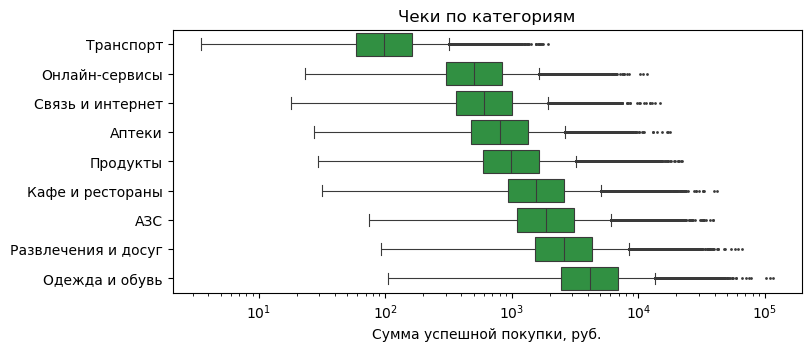

In [27]:
big = purch[amt_out]
print("Топ-категории среди «выбросов» по сумме:", big.category.value_counts(normalize=True).round(2).head(3).to_dict())
print("Клиентов с такими операциями:", big.client_id.nunique(), "из", purch.client_id.nunique(),
      "| максимум операций у одного клиента:", int(big.client_id.value_counts().max()))
print("Доход выше границы — какие сегменты?",
      clients[clients.monthly_income > clients.groupby("segment").monthly_income.transform(lambda s: tukey(s.dropna())[1])].segment.value_counts().to_dict())

# Чувствительность
print("\nМедиана чека, руб.: все успешные =", purch.amount_rub.median(),
      "| без помеченных =", purch.loc[~amt_out, "amount_rub"].median())
print("Среднее чека, руб.: все =", purch.amount_rub.mean(), "| без помеченных =", purch.loc[~amt_out, "amount_rub"].mean().round(1))

fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
order = purch.groupby("category").amount_rub.median().sort_values().index
sns.boxplot(data=purch, y="category", x="amount_rub", order=order, color= "#21A038" , fliersize=1, ax=ax, linewidth=0.8)
ax.set_xscale("log")
ax.set_title("Чеки по категориям")
ax.set_xlabel("Сумма успешной покупки, руб."); ax.set_ylabel("")
plt.show()

то что пометели как "выбросы" вытянуты, но лежат в пределах логики категории

**Решение по выбросам**

* **Суммы операций.** Помеченные "выбросы" - это правый хвост лог-нормального распределения чеков (одежда, развлечения), а не ошибки:
  не привязаны к одному клиенту или дню, максимум 115 тыс. руб. для категории "Одежда и обувь" - правдоподобная покупка.
  Источник проверить нельзя. **Оставляем**.
  Чувствительность проверена: без помеченных операций медиана чека меняется на −6% (1 085 → 1017 руб.), среднее — на −16% (1 887 → 1 587 руб.): среднее хвост "тянет", поэтому для чеков используем **медиану и МКР**.
  Метрика активности — число операций, на суммы не опирается.
* **Доход.** Высокие значения в сегментах Private/Премиальный - реальная неоднородность клиентов, а не ошибка. **Оставляем**,
  описываем медианой и МКР.
* **Сверхактивные клиенты** - оставляем, в сводках по группам используем суммы и медианы, а не средние.

In [28]:
n_big = int(amt_out.sum())
add_log("amount_rub", "суммы выше границы Тьюки внутри своей категории",
        "успешные покупки, amount_rub > Q3+1.5·МКР по категории", n_big,
        f"до {purch.amount_rub.max():,.0f} руб.".replace(",", " "), "оставлено", "без изменений",
        "хвост лог-нормального чека, не привязан к клиенту/дню; причину ошибки установить не удалось, исходник сохранён; "
        "для чеков берём медиану/МКР, чувствительность проверена")
n_inc_out = int(clients.monthly_income.gt(clients.groupby("segment").monthly_income.transform(lambda s: tukey(s.dropna())[1])).sum())
add_log("monthly_income", "высокие доходы выше границы Тьюки внутри сегмента", "monthly_income > Q3+1.5·МКР по сегменту",
        n_inc_out, "до 999 999 руб.", "оставлено", "без изменений",
        "реальная неоднородность клиентов Private/Премиальный; доход используется описательно (медиана, МКР)")

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [29]:
funnel_txn = [("в файле", len(df_txn))]
funnel_txn.append(("− полные дубли", -n_tx_full))
funnel_txn.append(("− повтор txn_id (копия без времени)", -n_tx_id))

in_period = (txn.txn_datetime >= DATA_START) & (txn.txn_datetime < DATA_END + pd.Timedelta(days=1))
n_out = int((~in_period).sum())
out_ex = txn.loc[~in_period, "txn_datetime"]
add_log("txn_datetime", "операции вне периода данных (2023-12 и 2025-07…2026-08, txn_id вида 99xxxx)", "txn_datetime вне [2024-01-01; 2025-06-30]",
        n_out, f"{out_ex.min():%Y-%m-%d} … {out_ex.max():%Y-%m-%d}", "удалено", "нет",
        "по описанию данные охватывают 2024-01-01…2025-06-30; даты из будущего (после выгрузки) невозможны; операции вне окон нельзя отнести ни к базе, ни к оценке")
txn = txn[in_period].reset_index(drop=True)
funnel_txn.append(("− вне периода", -n_out))
funnel_txn.append(("= операций после очистки", len(txn)))

# статус клиента относительно справочника 
txn["client_status"] = np.select(
    [txn.client_id.isin(conflict_ids), txn.client_id.isin(clients.client_id)],
    ["id_conflict", "in_reference"], default="not_in_reference")
txn["is_purchase"] = txn.status.eq("успешно")
funnel_txn.append(("  из них успешных покупок", int(txn.is_purchase.sum())))
funnel_txn.append(("  из них успешных покупок клиентов справочника (без конфликтных id)", int((txn.is_purchase & txn.client_status.eq("in_reference")).sum())))

funnel_df = pd.DataFrame(funnel_txn, columns=["шаг (операции)", "строк"])
display(funnel_df)
print(txn.client_status.value_counts().to_dict())

add_log("txn (операции клиентов вне справочника)", "клиенты не найдены в справочнике действующих", "client_id ∉ clients",
        int(txn.client_status.eq("not_in_reference").sum()), f"{orph_clients} client_id", "оставлено (помечено)",
        "client_status = not_in_reference; в расчёт кампании не входят",
        "это ушедшие из банка клиенты (операции исчезают к 2025-03): кампания невозможна, но их операции объясняют часть падения общего объёма")

,шаг (операции),строк
0,в файле,627703
1,− полные дубли,-1256
2,− повтор txn_id (копия без времени),-244
3,− вне периода,-81
4,= операций после очистки,626122
5,из них успешных покупок,606196
6,из них успешных покупок клиентов справочника...,578210


{'in_reference': 597219, 'not_in_reference': 27331, 'id_conflict': 1572}


In [30]:
# Воронка по клиентам 
funnel_cl = [("строк в справочнике", len(df_clients)),
             ("− полные дубли", -n_cl_full),
             ("= уникальных клиентов, пригодных к анализу", clients.client_id.nunique())]
display(pd.DataFrame(funnel_cl, columns=["шаг (клиенты)", "клиентов"]))

,шаг (клиенты),клиентов
0,строк в справочнике,5728
1,− полные дубли,-55
2,"= уникальных клиентов, пригодных к анализу",5673


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [31]:
# Журнал собирался по ходу раздела 3
cleaning_log = pd.DataFrame(log_rows, columns=LOG_COLUMNS)
print("Решений в журнале:", len(cleaning_log))
cleaning_log[["field", "issue", "n_rows", "action"]]

Решений в журнале: 20


,field,issue,n_rows,action
0,файлы (оба),разные кодировка/разделитель/десятичный знак,633431,исправлено
1,txn_datetime,время отсутствует в части записей (только дата),50447,оставлено
2,"city, segment","один id, две разные записи (разные city и/или ...",26,Замена на NaN
3,client_id,полные дубли строки в справочнике,55,удалено
4,txn_id,полные дубли операций (все поля совпадают),1256,удалено
5,txn_id,"тот же txn_id, различие только в точности врем...",244,удалено
6,city,"разнобой написания города (регистр, «г.», проб...",1665,нормализация
7,category,"разнобой написания категории (регистр, «/» вме...",51972,нормализация
8,amount,суммы EUR/USD записаны в валюте операции,2592,исправлено
9,mcc_code,код МСС не соответствует категории,1615,исправлено


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

In [32]:
# Таблица клиента, к которой будем добавлять признаки
ref = clients.set_index("client_id").copy()

purch_ref = txn[txn.is_purchase & txn.client_status.eq("in_reference")].copy()
purch_ref["month"] = purch_ref.txn_datetime.dt.to_period("M")

# число успешных покупок по клиентам и месяцам
ops = purch_ref.groupby(["client_id", "month"]).size().unstack(fill_value=0)
ops = ops.reindex(columns=ALL_MONTHS, fill_value=0)

ref["base_pm"] = ops[BASE_MONTHS].mean(axis=1).fillna(0)
ref["eval_pm"] = ops[EVAL_MONTHS].mean(axis=1).fillna(0)

def describe_robust(s, name):
    s = s.dropna()
    med = s.median()
    mean = s.mean()
    cv = (100 * s.std() / mean) if mean != 0 else np.nan
    
    return pd.Series({
        "признак": name, "n": len(s), "среднее": mean, "медиана": med, "ст.откл.": s.std(),
        "МКР": s.quantile(.75) - s.quantile(.25), "МАО": (s - med).abs().median(),
        "асимметрия": s.skew(), "CV, %": cv
    })

ticket = purch_ref.amount_rub
desc = pd.DataFrame([
    describe_robust(ref.age, "возраст, лет"),
    describe_robust(ref.tenure_years, "стаж в банке, лет"),
    describe_robust(ref.monthly_income, "доход, руб./мес. (без пропусков)"),
    describe_robust(ref.base_pm, "операций в месяц (2024)"),
    describe_robust(ticket, "сумма покупки, руб."),
]).set_index("признак").round(2)

display(desc)

,n,среднее,медиана,ст.откл.,МКР,МАО,асимметрия,"CV, %"
признак,,,,,,,,
"возраст, лет",5673,53.64,51.54,14.21,19.37,9.52,0.56,26.50
"стаж в банке, лет",5673,7.88,7.92,3.23,4.79,2.39,-0.05,41.01
"доход, руб./мес. (без пропусков)",5101,98653.89,74700.00,83532.66,54600.00,24500.00,3.91,84.67
операций в месяц (2024),5647,6.05,5.33,4.49,4.92,2.42,1.56,74.32
"сумма покупки, руб.",578210,1888.48,1087.14,2578.56,1778.01,735.30,4.92,136.54


**Выбор мер центра и разброса (обоснование).**

* **Возраст, стаж.** Асимметрия небольшая (0,5 у возраста, ≈0 у стажа), тяжёлых хвостов нет → среднее и стандартное отклонение допустимы; медиана и МКР дают близкие значения — приводим обе пары.
* **Доход.** Асимметрия > 2, среднее ≫ медианы (тянет хвост Private/Премиальный) → **медиана и МКР**. Среднее вводит в заблуждение.
* **Операций в месяц** и **сумма покупки.** Сильная правая асимметрия, CV ≫ 50% → **медиана и МКР/МАО**; сравнивать группы по сумме чеков будем медианами.
* **Оценка удовлетворённости (1–5) — порядковая шкала:** только медиана и доли по градациям.

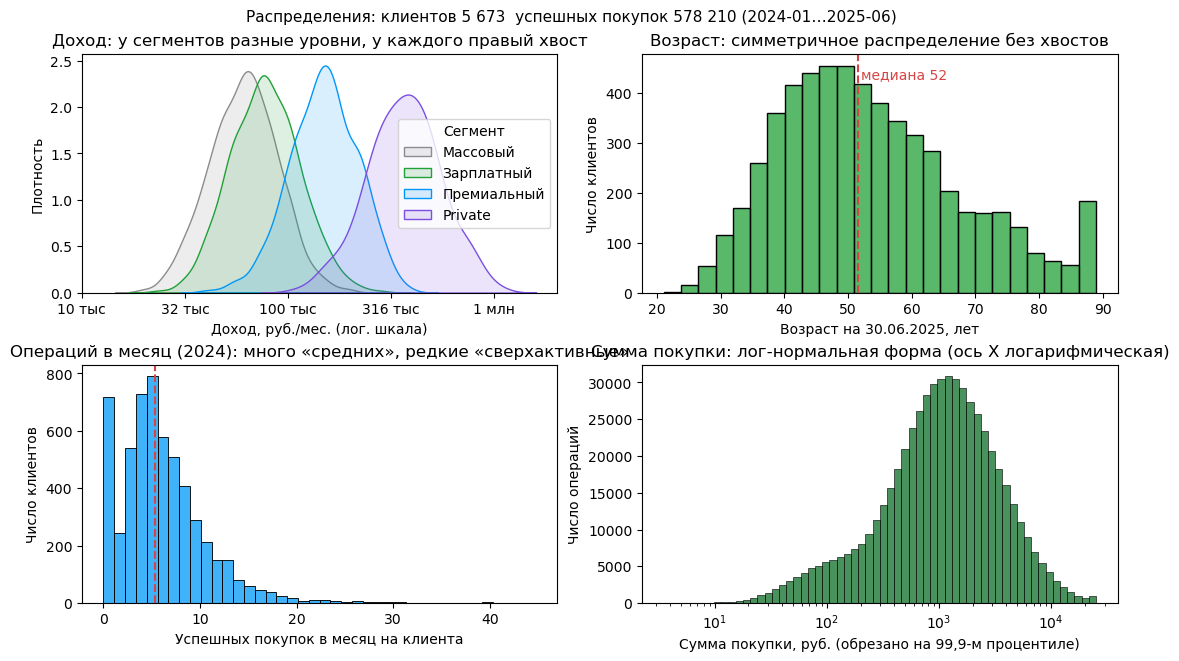

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), layout="constrained")

# доход по сегментам - логарифмическая шкала, т.к. хвост длинный
for seg, color in zip(["Массовый", "Зарплатный", "Премиальный", "Private"], ["#8C8C8C", "#21A038", "#0098F8", "#7A4FE0"]):
    sns.kdeplot(np.log10(ref.loc[ref.segment == seg, "monthly_income"].dropna()), ax=axes[0, 0], label=seg, color=color, fill=True, alpha=.15)
axes[0, 0].set_xticks([4, 4.5, 5, 5.5, 6]); axes[0, 0].set_xticklabels(["10 тыс", "32 тыс", "100 тыс", "316 тыс", "1 млн"])
axes[0, 0].set_title("Доход: у сегментов разные уровни, у каждого правый хвост")
axes[0, 0].set_xlabel("Доход, руб./мес. (лог. шкала)"); axes[0, 0].set_ylabel("Плотность"); axes[0, 0].legend(title="Сегмент")

# возраст
sns.histplot(ref.age, bins=25, color="#21A038", ax=axes[0, 1])
axes[0, 1].axvline(ref.age.median(), color="#D64545", ls="--"); axes[0, 1].text(ref.age.median() + .5, axes[0, 1].get_ylim()[1] * .9, f"медиана {ref.age.median():.0f}", color="#D64545")
axes[0, 1].set_title("Возраст: симметричное распределение без хвостов"); axes[0, 1].set_xlabel("Возраст на 30.06.2025, лет"); axes[0, 1].set_ylabel("Число клиентов")

# операций в месяц
sns.histplot(ref.base_pm, bins=40, color= "#0098F8", ax=axes[1, 0])
axes[1, 0].axvline(ref.base_pm.median(), color="#D64545", ls="--")
axes[1, 0].set_title("Операций в месяц (2024): много «средних», редкие «сверхактивные»")
axes[1, 0].set_xlabel("Успешных покупок в месяц на клиента"); axes[1, 0].set_ylabel("Число клиентов")

# чеки
sns.histplot(ticket.clip(upper=ticket.quantile(.999)), bins=60, log_scale=(True, False), color="#0D6E27", ax=axes[1, 1])
axes[1, 1].set_title("Сумма покупки: лог-нормальная форма (ось X логарифмическая)")
axes[1, 1].set_xlabel("Сумма покупки, руб. (обрезано на 99,9-м процентиле)"); axes[1, 1].set_ylabel("Число операций")
fig.suptitle(f"Распределения: клиентов {len(ref):,}, успешных покупок {len(ticket):,} (2024-01…2025-06)".replace(",", " "), fontsize=11)
plt.show()

### 5.2. Частотные характеристики категориальных признаков

In [34]:
def freq(s, name, order=None):
    """Частотная таблица: n, доля (знаменатель — все наблюдения s), накопленная доля (только для упорядоченных)."""
    vc = s.value_counts(dropna=False)
    if order is not None:
        vc = vc.reindex(order)
    out = pd.DataFrame({"n": vc, "доля, %": (vc / vc.sum() * 100).round(1)})
    out.index.name = name
    return out

def share(n, d):
    return f"{n:,} из {d:,} ({n / d:.1%})".replace(",", " ")

for col, order in [("segment", ["Массовый", "Зарплатный", "Премиальный", "Private"]),
                   ("loyalty_tier", ["Базовый", "Серебро", "Золото", "Платина"]),
                   ("card_type", None), ("city", None), ("income_source", None),
                   ("has_mobile_app", None), ("marketing_opt_in", None)]:
    t = freq(ref[col], col, order)
    if col == "loyalty_tier":
        t["накопл., %"] = t["доля, %"].cumsum().round(1)     # накопление осмысленно только для упорядоченной шкалы
    print(f"n = {len(ref)}"); display(t)

# порядковая шкала satisfaction_score: доли по градациям среди ответивших + медиана (среднее не используем)
sat = ref.satisfaction_score.dropna().astype(int)
print("satisfaction_score: ответили", share(len(sat), len(ref)), "| медиана =", sat.median(), "| мода =", sat.mode()[0])
display(freq(sat, "оценка", [1, 2, 3, 4, 5]).assign(**{"накопл., %": lambda d: d["доля, %"].cumsum().round(1)}))

n = 5673


,n,"доля, %"
segment,,
Массовый,2964,52.2
Зарплатный,1587,28.0
Премиальный,910,16.0
Private,212,3.7


n = 5673


,n,"доля, %","накопл., %"
loyalty_tier,,,
Базовый,2940,51.8,51.8
Серебро,1517,26.7,78.5
Золото,929,16.4,94.9
Платина,287,5.1,100.0


n = 5673


,n,"доля, %"
card_type,,
Дебетовая,3976,70.1
Кредитная,1221,21.5
Премиальная,476,8.4


... (6 outputs left out)

n = 5673


,n,"доля, %"
marketing_opt_in,,
True,5003,88.2
False,670,11.8


satisfaction_score: ответили 2 242 из 5 673 (39.5%) | медиана = 3.0 | мода = 5


,n,"доля, %","накопл., %"
оценка,,,
1,301,13.4,13.4
2,448,20.0,33.4
3,458,20.4,53.8
4,433,19.3,73.1
5,602,26.9,100.0


Сегмент × приложение, абсолютные частоты:


has_mobile_app,False,True
segment,,
Private,76,136
Зарплатный,625,962
Массовый,1145,1819
Премиальный,343,567


Сегмент × приложение, % по строкам (знаменатель — клиенты сегмента):


has_mobile_app,False,True
segment,,
Private,35.8,64.2
Зарплатный,39.4,60.6
Массовый,38.6,61.4
Премиальный,37.7,62.3


V Крамера: сегмент~приложение = 0.016 | сегмент~лояльность = 0.374 | сегмент~тип карты = 0.416 | сегмент~город = 0.183


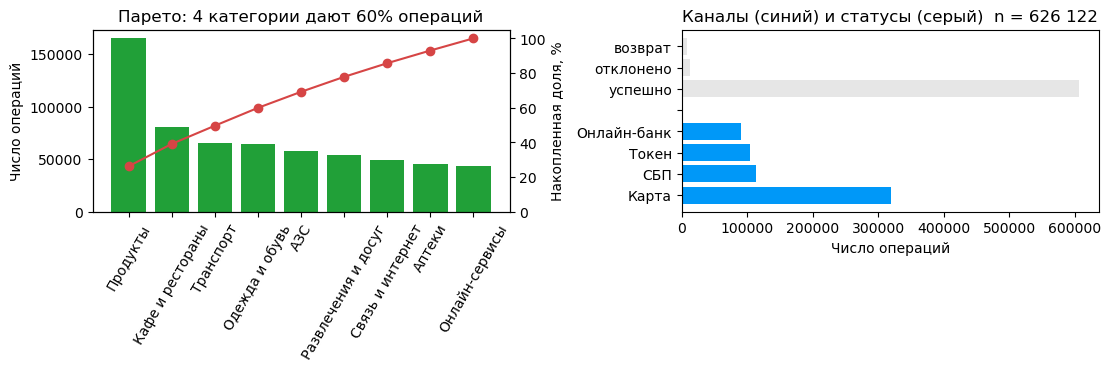

In [35]:
# Таблицы сопряжённости: сначала абсолютные частоты, затем нормировка ПО СТРОКАМ (знаменатель = число клиентов сегмента)
def cramers_v(ct):
    """V Крамера:  V = sqrt(chi2 / (n·min(r−1, c−1)))."""
    obs = ct.values.astype(float); n = obs.sum()
    exp = obs.sum(1, keepdims=True) @ obs.sum(0, keepdims=True) / n
    chi2 = ((obs - exp) ** 2 / exp).sum()
    return np.sqrt(chi2 / (n * (min(obs.shape) - 1)))

ct = pd.crosstab(ref.segment, ref.has_mobile_app)
print("Сегмент × приложение, абсолютные частоты:"); display(ct)
print("Сегмент × приложение, % по строкам (знаменатель — клиенты сегмента):"); display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))
print("V Крамера: сегмент~приложение =", round(cramers_v(ct), 3),
      "| сегмент~лояльность =", round(cramers_v(pd.crosstab(ref.segment, ref.loyalty_tier)), 3),
      "| сегмент~тип карты =", round(cramers_v(pd.crosstab(ref.segment, ref.card_type)), 3),
      "| сегмент~город =", round(cramers_v(pd.crosstab(ref.segment, ref.city)), 3))

# Парето по категориям трат и частоты каналов/статусов
cat_n = txn.category.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
ax = axes[0]
ax.bar(cat_n.index, cat_n.values, color="#21A038")
ax.set_ylabel("Число операций"); ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx(); ax2.plot(cat_n.index, cat_n.cumsum() / cat_n.sum() * 100, color="#D64545", marker="o"); ax2.set_ylabel("Накопленная доля, %"); ax2.set_ylim(0, 105)
ax2.grid(False); ax.set_title(f"Парето: 4 категории дают {cat_n.iloc[:4].sum() / cat_n.sum():.0%} операций")
ch = txn.channel.value_counts(); st = txn.status.value_counts()
axes[1].barh(list(ch.index) + [""] + list(st.index), list(ch.values) + [0] + list(st.values), color=["#0098F8"] * len(ch) + ["#8C8C8C"] + ["#E6E6E6"] * len(st))
axes[1].set_xlabel("Число операций"); axes[1].set_title(f"Каналы (синий) и статусы (серый), n = {len(txn):,}".replace(",", " "))
plt.show()

### 5.3. Динамика по месяцам

Сезонный индекс 2024 (1.0 = среднемесячный): {1: 0.71, 2: 0.9, 3: 1.04, 4: 1.01, 5: 0.92, 6: 1.0, 7: 1.02, 8: 1.06, 9: 1.01, 10: 1.04, 11: 1.02, 12: 1.27}
S6 (янв–июнь) = 0.930; S3 (апр–июнь) = 0.973


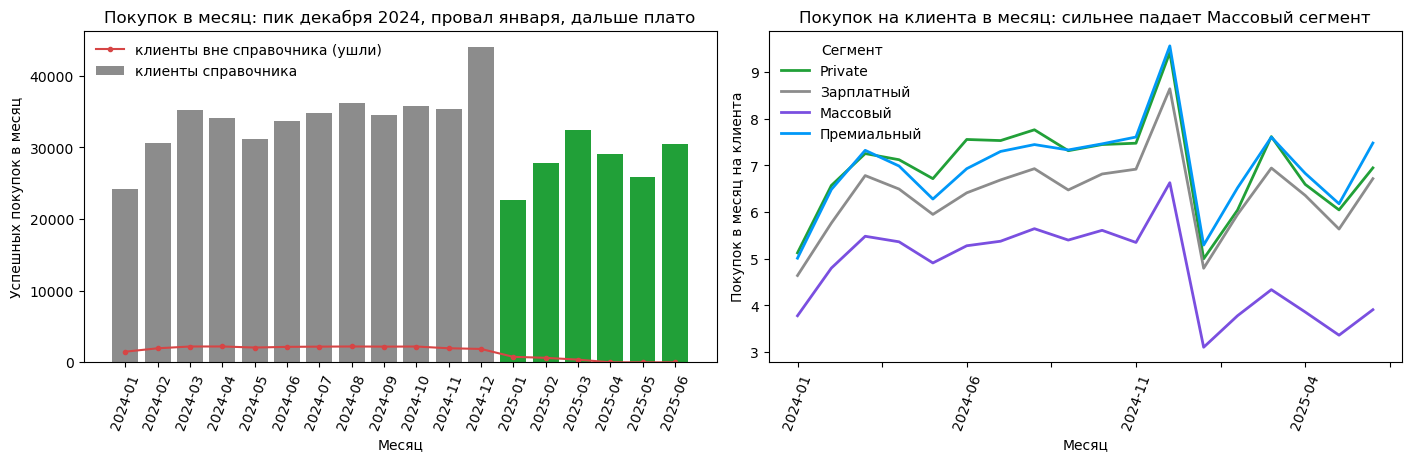

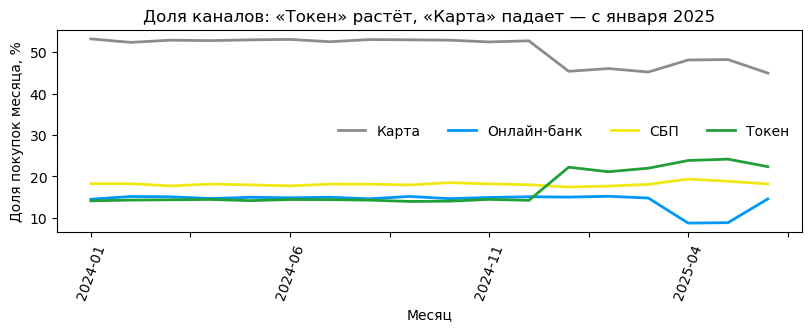

In [36]:
# Клиенты с картой, открытой ДО 2024 года, имеют полный базовый год. По ним оцениваем сезонность 2024 года.
ref["full_base"] = ref.card_open_date <= "2023-12-31"
tot_m = ops.loc[ref.full_base, BASE_MONTHS].sum()
season = tot_m / tot_m.mean()
season.index = [p.month for p in season.index]
S6 = season.loc[1:6].mean()
S3 = season.loc[4:6].mean()
print("Сезонный индекс 2024 (1.0 = среднемесячный):", season.round(2).to_dict())
print(f"S6 (янв–июнь) = {S6:.3f}; S3 (апр–июнь) = {S3:.3f}")

ref["ratio6_raw"] = ref.eval_pm / ref.base_pm.replace(0, np.nan)             # наивное отношение 2025 к 2024
ref["ratio6"] = ref.ratio6_raw / S6                                          # с поправкой на сезонность
ref["eval3_pm"] = ops[pd.period_range("2025-04", "2025-06", freq="M")].mean(axis=1)
ref["ratio3"] = ref.eval3_pm / (ref.base_pm.replace(0, np.nan) * S3)         # последний квартал оценки
ref["ratio3_raw"] = ref.eval3_pm / ref.base_pm.replace(0, np.nan)            # то же без поправки для проверки устойчивости

# динамика числа покупок
m_all = purch_ref.groupby("month").size().reindex(ALL_MONTHS)
m_orph = txn[txn.is_purchase & txn.client_status.eq("not_in_reference")].groupby(txn.txn_datetime.dt.to_period("M")).size().reindex(ALL_MONTHS, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")

ax = axes[0]
x = [str(p) for p in ALL_MONTHS]
ax.bar(x, m_all.values, color=["#8C8C8C" if p in BASE_MONTHS else "#21A038" for p in ALL_MONTHS], label="клиенты справочника")
ax.plot(x, m_orph.values, color="#D64545", marker="o", ms=3, label="клиенты вне справочника (ушли)")
ax.set_title("Покупок в месяц: пик декабря 2024, провал января, дальше плато")
ax.set_ylabel("Успешных покупок в месяц"); 
ax.set_xlabel("Месяц")
ax.tick_params(axis="x", rotation=70); ax.legend(frameon=False)

# индекс на клиента: покупок в месяц на одного клиента-справочника по сегментам
seg_idx = (ops.groupby(ref.segment).sum().T / ref.groupby("segment").size())
seg_idx.index = x
seg_idx.plot(ax=axes[1], color=["#21A038", "#8C8C8C", "#7A4FE0", "#0098F8"], lw=2)
axes[1].set_title("Покупок на клиента в месяц: сильнее падает Массовый сегмент")
axes[1].set_ylabel("Покупок в месяц на клиента"); 
axes[1].set_xlabel("Месяц")
axes[1].tick_params(axis="x", rotation=70); axes[1].legend(title="Сегмент", frameon=False)

# структура каналов во времени
ch_m = purch_ref.groupby(["month", "channel"]).size().unstack().reindex(ALL_MONTHS)
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
(ch_m.div(ch_m.sum(axis=1), axis=0) * 100).set_axis(x).plot(ax=ax, lw=2, color=["#8C8C8C", "#0098F8", "#F1E813", "#21A038"])
ax.set_title("Доля каналов: «Токен» растёт, «Карта» падает — с января 2025")
ax.set_ylabel("Доля покупок месяца, %"); 
ax.set_xlabel("Месяц"); 
ax.tick_params(axis="x", rotation=70); 
ax.legend(frameon=False, ncol=4)
plt.show()

**Вывод**
1. Покупок в декабре 2024 заметно выше среднего месяца, в январе - ниже. Если сравнивать "6 месяцев 2025" со "средним по 12 месяцам 2024"
   без поправки, падение будет завышено сезонностью - поэтому в метрике будет введена сезонная поправка.
2. Часть падения общего объёма даёт уход клиентов, которых нет в справочнике (красная линия): их операции исчезают к марту 2025.
3. С января 2025 доля "Токен" растёт, а "Карта" падает: клиенты переходят на оплату смартфоном. Значит, метрика, считающая только канал "Карта",
   завысила бы падение - нужен учёт всех каналов.
4. Падение по месяцам - сильнее всего в Массовом сегменте.

### 5.4. Разрезы и связи между признаками

In [37]:
def seg_ratio(df, keys):
    """Агрегированное отношение (сумма операций 2025 / ожидаемое по базе), n и средний базовый объём. Только клиенты с полной базой."""
    d = df[df.full_base & (df.base_pm >= 2)]
    g = d.groupby(keys, observed=True).agg(n=("base_pm", "size"), base=("base_pm", "sum"), ev=("eval_pm", "sum"))
    g["ratio"] = g.ev / (g.base * S6)
    return g[["n", "ratio"]].round(3)

print("Клиенты с полной базой и ≥2 покупок в месяц; ratio = (покупок в мес. 2025) / (ожидаемо по 2024 с учётом сезона).")
for key in ["segment", "has_mobile_app", "loyalty_tier", "card_type", "income_source", "city"]:
    display(seg_ratio(ref, key).T)
display(seg_ratio(ref, ["segment", "has_mobile_app"]).unstack(0)["ratio"])

Клиенты с полной базой и ≥2 покупок в месяц; ratio = (покупок в мес. 2025) / (ожидаемо по 2024 с учётом сезона).


segment,Private,Зарплатный,Массовый,Премиальный
n,179.000,1300.000,2519.000,758.000
ratio,0.908,0.961,0.728,0.964


has_mobile_app,False,True
n,1845.000,2911.0
ratio,0.769,0.9


loyalty_tier,Базовый,Золото,Платина,Серебро
n,2481.000,759.000,242.000,1274.000
ratio,0.802,0.958,0.908,0.862


card_type,Дебетовая,Кредитная,Премиальная
n,3334.00,1022.000,400.000
ratio,0.83,0.882,0.933


income_source,Зарплата в другом банке,Зарплата в нашем банке,Не указан
n,1286.000,2117.00,1353.000
ratio,0.806,0.91,0.797


city,Екатеринбург,Казань,Москва,Нижний Новгород,Новосибирск,Санкт-Петербург
n,564.000,614.000,1347.000,580.000,822.000,829.000
ratio,0.864,0.873,0.873,0.885,0.751,0.866


segment,Private,Зарплатный,Массовый,Премиальный
has_mobile_app,,,,
False,0.819,0.909,0.620,0.894
True,0.956,0.992,0.791,1.001


,"доля Массового, %",ratio всех,ratio только Массовый
city,,,
Новосибирск,87.0,0.751,0.718
Екатеринбург,46.0,0.864,0.717
Санкт-Петербург,47.0,0.866,0.738
Казань,46.0,0.873,0.732
Москва,44.0,0.873,0.736
Нижний Новгород,43.0,0.885,0.730


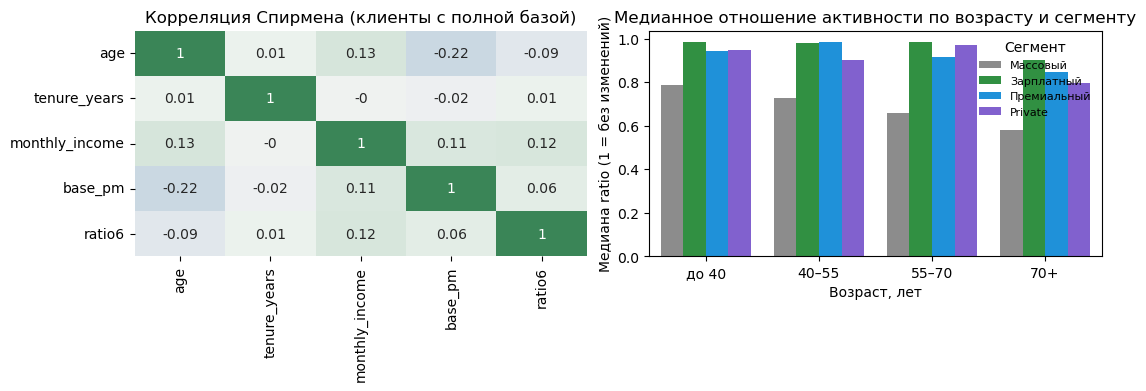

In [38]:
mass_share = ref.groupby("city").segment.apply(lambda s: (s == "Массовый").mean())
city_ratio = seg_ratio(ref, "city").ratio
city_mass_ratio = seg_ratio(ref[ref.segment == "Массовый"], "city").ratio
cmp = pd.DataFrame({"доля Массового, %": (mass_share * 100).round(0), "ratio всех": city_ratio, "ratio только Массовый": city_mass_ratio})
display(cmp.sort_values("ratio всех"))

# Корреляции Спирмена между числовыми признаками
num = ref.loc[ref.full_base & (ref.base_pm >= 2), ["age", "tenure_years", "monthly_income", "base_pm", "ratio6"]]
rho = num.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
sns.heatmap(rho.round(2), annot=True, cmap=sns.diverging_palette(240, 140, as_cmap=True), vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Корреляция Спирмена (клиенты с полной базой)")
d = ref[ref.full_base & (ref.base_pm >= 2)].copy()
d["возраст"] = pd.cut(d.age, [0, 40, 55, 70, 100], labels=["до 40", "40–55", "55–70", "70+"])
sns.barplot(data=d, x="возраст", y="ratio6", hue="segment", estimator="median", errorbar=None, ax=axes[1],
            palette=["#8C8C8C", "#21A038", "#0098F8", "#7A4FE0"], order=["до 40", "40–55", "55–70", "70+"])
axes[1].set_title("Медианное отношение активности по возрасту и сегменту")
axes[1].set_ylabel("Медиана ratio (1 = без изменений)"); axes[1].set_xlabel("Возраст, лет"); axes[1].legend(title="Сегмент", frameon=False, fontsize=8)
plt.show()

**Что видно.**
1. Падение сосредоточено в Массовом сегменте, причём сильнее у клиентов без приложения; в Зарплатном/Премиальном/Private активность почти на уровне базы.
2. Различие по городам: в Казани больше Массового сегмента; внутри Массового города практически не различаются.
3. Корреляции признаков клиента с изменением активности слабые (|ρ| < 0,22): падение определяется сегментом и каналами/категориями, а не одним числовым признаком.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

**Определение.**

Активность клиента = число успешных покупок по картам, все каналы:
(Карта, Токен, СБП, Онлайн-банк) в расчёте на месяц.

1) Базовая активность клиента: `base_pm` = (покупок за 2024 год) / 12.
2) Оцениваемая: `eval_pm` = (покупок за январь–июнь 2025) / 6. Окна разной длины — поэтому всегда средние в месяц, а не суммы.
3) Сезонная поправка -- календарь неравномерен: декабрь - пик, январь - минимум. Сезонный индекс `season_m` = покупки в месяце 2024 /
  среднемесячные покупки 2024 (только 2024 год и только клиенты с полным базовым годом).
  `S6` = среднее `season_m` за январь–июнь. Ожидаемый уровень "без изменений" = `base_pm · S6`.
4) Индекс активности `ratio6 = eval_pm / (base_pm · S6)`: 1 - без изменений, 0,5 - упала вдвое. Для "конца периода" тот же расчёт за апрель–июнь: `ratio3`.

**Почему**
1. Число операций, а не сумма: не зависит от валюты и крупных чеков; на данных медианный чек не изменился, т.е. клиенты стали пользоваться картой реже, а не платить меньше.
2. Все каналы, а не "Карта": часть клиентов перешла с пластика на оплату через "Токен". Метрика только по "Карте" назвала бы их "падением".
3. Успешные покупки: отклонённые - деньги не списаны; возвраты - отмена покупки.
4. Относительно самого клиента: у клиентов разный уровень трат, единый порог по абсолютной величине опасен.

**Какое снижение метрика не увидит**
* Снижение суммы при неизменном числе операций (клиент платит так же часто, но на меньшие суммы).
* Клиентов с нулевой/малой базой (карта открыта в 2024–2025, <2 покупок в месяц): падение от низов неопределенно, но и не критично.
* Уход на другую карту/в наличные - в данных виден только "ноль", а причина нет; метрика не отличает "ушёл в другой банк" от "стал реже платить".
* Падение "внутри месяца" (последние дни июня) и изменение состава трат при том же числе покупок.

клиентов с полной базой и ≥2 покупок/мес: 4756 из 5673 (83.8%)
ratio6 (с поправкой): квантили 5/25/50/75/95 % = [0.26, 0.5, 0.85, 1.09, 1.52]
ratio6_raw (без поправки): квантили            = [0.24, 0.47, 0.79, 1.02, 1.41]
По всей клиентской базе (суммарно): ratio без поправки = 0.792; с поправкой = 0.852


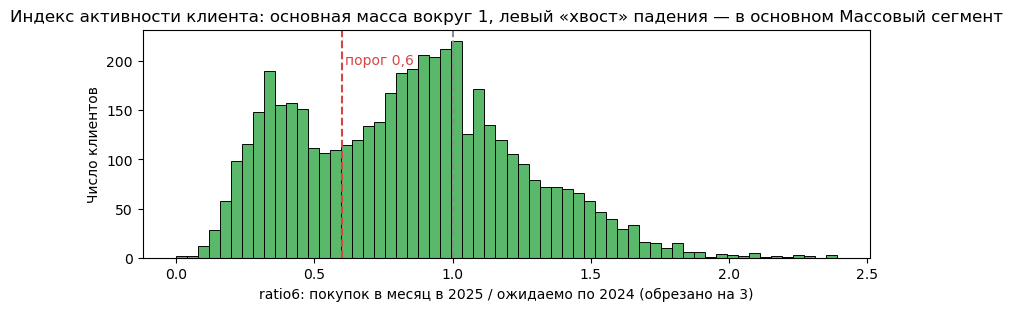

In [39]:
# Распределение индекса и чувствительность к сезонной поправке
d = ref[ref.full_base & (ref.base_pm >= 2)]
print(f"клиентов с полной базой и ≥2 покупок/мес: {len(d)} из {len(ref)} ({len(d) / len(ref):.1%})")
print("ratio6 (с поправкой): квантили 5/25/50/75/95 % =", d.ratio6.quantile([.05, .25, .5, .75, .95]).round(2).tolist())
print("ratio6_raw (без поправки): квантили            =", d.ratio6_raw.quantile([.05, .25, .5, .75, .95]).round(2).tolist())
print(f"По всей клиентской базе (суммарно): ratio без поправки = {d.eval_pm.sum() / d.base_pm.sum():.3f}; с поправкой = {d.eval_pm.sum() / d.base_pm.sum() / S6:.3f}")
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
sns.histplot(d.ratio6.clip(upper=3), bins=60, color="#21A038", ax=ax)
ax.axvline(1, color="#8C8C8C", ls="--"); ax.axvline(0.6, color="#D64545", ls="--"); ax.text(0.61, ax.get_ylim()[1] * .85, "порог 0,6", color="#D64545")
ax.set_title("Индекс активности клиента: основная масса вокруг 1, левый «хвост» падения — в основном Массовый сегмент")
ax.set_xlabel("ratio6: покупок в месяц в 2025 / ожидаемо по 2024 (обрезано на 3)"); ax.set_ylabel("Число клиентов")


plt.show()

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

Правило каждой группы состоит из двух частей: 

1) кто это (признак клиента или характеристика его трат)
2) что с ними произошло (характер падения). Порог величины падения - лишь уточнение, а не содержание.

**Допуск клиента к сравнению (общий для всех групп).**
1. клиент в справочнике;
2. карта открыта до 2024 года (полный базовый год) - иначе "падение" нельзя отличить от разгона новой карты;
3. `base_pm ≥ 2` покупок в месяц (≥ 24 за 2024 год) - при меньшем уровне индекс шумит: 1–2 случайных операции дают −50%;
4. есть согласие на маркетинговую коммуникацию (`marketing_opt_in = Да`) - без него кампания невозможна.

**Признаки падения**:
* `ratio6` - индекс за январь–июнь 2025; `ratio3` - за апрель–июнь ("к концу периода");

**Четыре группы:**

| № | Кто это | Что произошло |
|---|---|---|
| Г1 | сегмент "Массовый", **нет** мобильного приложения | **общее затухание** всех трат: `ratio6 ≤ 0,6` и `ratio3 ≤ 0,5` (к концу периода хуже, чем в среднем) |
| Г2 | сегмент "Массовый", **есть** мобильное приложение | **общее снижение** частоты всех трат (те же пороги), несмотря на переход части оплат на «Токен» |
| Г3 | сегменты "Зарплатный", "Премиальный", "Private", **нет** мобильного приложения| общее снижение частоты всех трат (умеренное падение: `ratio6 ≤ 0,85`, так как для ценных клиентов даже потеря 15% активности критична |
| Г4 | любой сегмент, активно платил физической картой (card_base_pm ≥ 0,85), но не перешел на "Токен" (token_share ≤ 0,05) | общее снижение частоты операций `ratio6 ≤ 0,8`, не компенсированное переходом в цифровой канал|

**Порядок разрешения конфликтов:** Г1 → Г2 → Г3 → Г4.

In [40]:
# признаки для Г4: Карта без Токена 
card_base = purch_ref[(purch_ref.month.isin(BASE_MONTHS)) & (purch_ref.channel == "Карта")].groupby("client_id").size()
ref["card_base_pm"] = ref.index.map(card_base).fillna(0) / 12

token_all = purch_ref[purch_ref.channel == "Токен"].groupby("client_id").size()
ref["token_cnt"] = ref.index.map(token_all).fillna(0)

token_purch = purch_ref[purch_ref.channel == "Токен"].groupby("client_id").size()
total_purch = purch_ref.groupby("client_id").size()

ref["token_share"] = (
    ref.index.map(token_purch) / 
    ref.index.map(total_purch)
).fillna(0)

In [41]:
MIN_BASE_PM = 2.0 # допуск: покупок в месяц в 2024
R6_MAX, R3_MAX = 0.60, 0.50 # для массового сегмента: индекс янв–июнь и апр–июнь
R6_MAX_NM, R3_MAX_NM = 0.85, 0.80

ref["eligible_base"] = ref.full_base & (ref.base_pm >= MIN_BASE_PM)
ref["opt_in"] = ref.marketing_opt_in
ref["broad_fall"] = (ref.ratio6 <= R6_MAX) & (ref.ratio3 <= R3_MAX)
ref["broad_fall_NM"] = (ref.ratio6 <= R6_MAX_NM) & (ref.ratio3 <= R3_MAX_NM)

purch_ref["per"] = np.where(purch_ref.month.isin(BASE_MONTHS), "base", "eval")

ref["rule_g1"] = ref.eligible_base & (ref.segment == "Массовый") & ~ref.has_mobile_app & ref.broad_fall
ref["rule_g2"] = ref.eligible_base & (ref.segment == "Массовый") & ref.has_mobile_app & ref.broad_fall
ref["rule_g3"] = (ref.eligible_base & 
                 (~ref.has_mobile_app) &  
                 (ref.segment != "Массовый")) & ref.broad_fall_NM


ref["rule_g4"] = (
    ref.eligible_base & 
    (ref.card_base_pm >= 0.85) &
    (ref.token_share <= 0.05) &
    (ref.ratio6 <= 0.80)
)


rules = ["rule_g1", "rule_g2", "rule_g3","rule_g4"]
cand = ref[ref.opt_in]
overlap = pd.DataFrame({a: {b: int((cand[a] & cand[b]).sum()) for b in rules} for a in rules})
print("Сколько клиентов с согласием подходит под правило (диагональ) и под пары правил:")
display(overlap)
print("Подходит под >1 правила:", int((cand[rules].sum(axis=1) > 1).sum()))

Сколько клиентов с согласием подходит под правило (диагональ) и под пары правил:


,rule_g1,rule_g2,rule_g3,rule_g4
rule_g1,435,0,0,105
rule_g2,0,391,0,59
rule_g3,0,0,266,55
rule_g4,105,59,55,327


Подходит под >1 правила: 219


In [42]:
G1 = "Г1 Массовый без приложения: затухание"
G2 = "Г2 Массовый с приложением: общее снижение"
G3 = "Г3 Ценные без приложения: общее снижение"
G4 = "Г4 Отказ от пластика без перехода на Токен"

ref["group"] = np.select(
    [ref.opt_in & ref.rule_g1, 
     ref.opt_in & ref.rule_g2, 
     ref.opt_in & ref.rule_g4,
     ref.opt_in & ref.rule_g3], 
    [G1, G2, G4, G3], 
    default=""
)

campaign = ref.loc[ref.group != "", ["group"]].reset_index()

assert campaign.client_id.is_unique                    
assert len(campaign) <= 2000                           
sizes = campaign.group.value_counts()
assert (sizes >= 150).all() and 3 <= len(sizes) <= 5   

print("Итого в кампании:", len(campaign))
display(sizes.to_frame("клиентов"))

Итого в кампании: 1200


,клиентов
group,
Г1 Массовый без приложения: затухание,435
Г2 Массовый с приложением: общее снижение,391
Г3 Ценные без приложения: общее снижение,211
Г4 Отказ от пластика без перехода на Токен,163


### 7.1. Кого в кампанию не берём и почему

In [43]:
n_ref = len(ref)
status = pd.Series("", index=ref.index, dtype="object")
def put(mask, label):
    global status
    status = status.mask(mask & (status == ""), label)

put(~ref.full_base, "Нет полного базового года: карта открыта в 2024–2025")
put(ref.base_pm < MIN_BASE_PM, "Мало операций в базе (<2 в месяц): падение не измерить")
put(~ref.opt_in, "Нет согласия на маркетинговую коммуникацию")

put(ref.group != "", "В кампании (Г1–Г4)")
put(ref.ratio6 >= 0.85, "Активность не сильно упала (индекс ≥ 0,85) или выросла")

card_cols = purch_ref.groupby(["client_id", "per", "channel"]).size().unstack(["per", "channel"], fill_value=0).reindex(ref.index, fill_value=0)
ref["card_b"] = card_cols[("base", "Карта")] / 12
ref["card_e"] = card_cols[("eval", "Карта")] / 6
ref["card_ratio"] = ref.card_e / (ref.card_b.replace(0, np.nan) * S6)
put((ref.ratio6 >= 0.70) & (ref.card_ratio <= 0.70), "Перешли с «Карты» на «Токен»: общая активность держится (падение только в пластике)")

put(ref.broad_fall, "Общее падение, но не попал в целевые группы")
put(status == "", "Умеренное снижение (индекс 0,6–0,85), не попал в целевые группы")

ref["exclusion_reason"] = status
excl = ref.exclusion_reason.value_counts().to_frame("клиентов")
excl["доля от клиентов справочника, %"] = (excl.клиентов / n_ref * 100).round(1)
display(excl)

print("Дополнительно (вне таблицы клиентов): клиентов вне справочника —", orph_clients, "(ушли; кампания невозможна);")

lost_aud = ref[(~ref.opt_in) & ref.eligible_base & (ref.rule_g1 | ref.rule_g2 | ref.rule_g3 | ref.rule_g4)]
print("Подошли бы под правила, но без согласия:", len(lost_aud), "клиентов")

,клиентов,"доля от клиентов справочника, %"
exclusion_reason,,
"Активность не сильно упала (индекс ≥ 0,85) или выросла",2117,37.3
В кампании (Г1–Г4),1200,21.2
Нет полного базового года: карта открыта в 2024–2025,772,13.6
"Умеренное снижение (индекс 0,6–0,85), не попал в целевые группы",600,10.6
Нет согласия на маркетинговую коммуникацию,570,10.0
Перешли с «Карты» на «Токен»: общая активность держится (падение только в пластике),188,3.3
Мало операций в базе (<2 в месяц): падение не измерить,133,2.3
"Общее падение, но не попал в целевые группы",93,1.6


Дополнительно (вне таблицы клиентов): клиентов вне справочника — 327 (ушли; кампания невозможна);
Подошли бы под правила, но без согласия: 181 клиентов


1. **Нет согласия на коммуникацию** - по условию заказчика связаться нельзя; часть из них подошла бы под правила (число выше).
2. **Карта открыта в 2024–2025** - нет базового года; рост «из нуля» нельзя отличить от настоящей динамики.
3. **Мало операций в 2024** (<2 в месяц) - индекс шумит.
4. **Клиенты вне справочника** ушли из банка к началу 2025.
5. **Перешли с «Карты» на «Токен»** - активность не упала, меняется способ оплаты; кампания им не нужна.
6. **Общее падение вне основных групп** - доля таких клиентов (≈3.2%) равна фоновому уровню индивидуальных колебаний, правило не отличает их от шума, группа получилась бы нестабильной.
7. **Умеренное снижение** - не дотягивает до порога падения; ресурс кампании ограничен.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [44]:
d = ref[ref.eligible_base]
tot_b, tot_e = d.base_pm.sum(), d.eval_pm.sum()
hyp = []

# H1: падение - только в канале «Карта» (клиенты ушли в «Токен»)?
cb = purch_ref[purch_ref.client_id.isin(d.index)].groupby(["channel", "per"]).size().unstack()
card_change = (cb.loc["Карта", "eval"] / 6) / (cb.loc["Карта", "base"] / 12) / S6 - 1
tok_change = (cb.loc["Токен", "eval"] / 6) / (cb.loc["Токен", "base"] / 12) / S6 - 1
tot_change = tot_e / (tot_b * S6) - 1
hyp.append(("H1. Падение только в канале «Карта», а в целом активность не упала",
            f"НЕ подтвердилась: «Карта» {card_change:+.0%}, «Токен» {tok_change:+.0%}, но суммарно по всем каналам {tot_change:+.0%} (n={len(d)}). "
            "Переход в «Токен» компенсирует лишь часть."))

# H2: Казань - причина падения?
km = d[d.segment == "Массовый"].groupby(d.city == "Казань").apply(lambda g: g.eval_pm.sum() / g.base_pm.sum() / S6)
hyp.append(("H2. Падение связано с городом (Казань хуже)",
            f"НЕ подтвердилась: по всем клиентам Казань {d[d.city == 'Казань'].eval_pm.sum() / d[d.city == 'Казань'].base_pm.sum() / S6:.2f} против "
            f"{d[d.city != 'Казань'].eval_pm.sum() / d[d.city != 'Казань'].base_pm.sum() / S6:.2f}, но внутри Массового сегмента Казань {km[True]:.2f} против {km[False]:.2f} — эффект города = состав сегмента."))

# H3: клиенты, давно не заходившие в приложение, снизили активность сильнее?
a = d[d.has_mobile_app]
a_old = a[a.months_since_login >= 6]; a_new = a[a.months_since_login <= 1]
r_old = a_old.eval_pm.sum() / a_old.base_pm.sum() / S6; r_new = a_new.eval_pm.sum() / a_new.base_pm.sum() / S6
hyp.append(("H3. Не заходят в приложение ≥6 мес. → активность упала сильнее",
            f"НЕ подтвердилась: ratio {r_old:.2f} (n={len(a_old)}) против {r_new:.2f} при входе ≤1 мес. назад (n={len(a_new)}); различие в пределах шума."))

# H4: упал средний чек, а не частота?
tk = purch_ref[purch_ref.client_id.isin(d.index)].groupby("per").amount_rub.median()
hyp.append(("H4. Клиенты стали платить меньшими суммами (упал чек)",
            f"НЕ подтвердилась: медианный чек 2025/2024 = {tk['eval'] / tk['base']:.2f} (≈ {tk['base']:.0f} → {tk['eval']:.0f} руб.); упала частота операций, а не размер покупки."))

# H5: низкая удовлетворённость -> падение?
lo_s = d[d.satisfaction_score.le(2).fillna(False)]; hi_s = d[d.satisfaction_score.ge(4).fillna(False)]
hyp.append(("H5. Недовольные (оценка 1–2) снижают активность сильнее довольных (4–5)",
            f"СЛАБО/не подтвердилась: ratio {lo_s.eval_pm.sum() / lo_s.base_pm.sum() / S6:.2f} (n={len(lo_s)}) против {hi_s.eval_pm.sum() / hi_s.base_pm.sum() / S6:.2f} (n={len(hi_s)}); "
            f"оценка есть только у {ref.satisfaction_answered.mean():.0%} клиентов, вывод ненадёжен."))

# H6: зарплата в другом банке - причина?
m = d[d.segment == "Массовый"]
o1 = m[m.income_source == "Зарплата в другом банке"]; o2 = m[m.income_source == "Зарплата в нашем банке"]
hyp.append(("H6. Внутри Массового сегмента падение больше у получающих зарплату в другом банке",
            f"НЕ подтвердилась: ratio {o1.eval_pm.sum() / o1.base_pm.sum() / S6:.2f} (n={len(o1)}) против {o2.eval_pm.sum() / o2.base_pm.sum() / S6:.2f} (n={len(o2)})."))
hyp = pd.DataFrame(hyp, columns=["гипотеза", "результат"])
pd.set_option("display.max_colwidth", 250)
display(hyp)

,гипотеза,результат
0,"H1. Падение только в канале «Карта», а в целом активность не упала","НЕ подтвердилась: «Карта» -26%, «Токен» +37%, но суммарно по всем каналам -15% (n=4756). Переход в «Токен» компенсирует лишь часть."
1,H2. Падение связано с городом (Казань хуже),"НЕ подтвердилась: по всем клиентам Казань 0.87 против 0.85, но внутри Массового сегмента Казань 0.73 против 0.73 — эффект города = состав сегмента."
2,H3. Не заходят в приложение ≥6 мес. → активность упала сильнее,НЕ подтвердилась: ratio 0.90 (n=1920) против 0.91 при входе ≤1 мес. назад (n=333); различие в пределах шума.
3,H4. Клиенты стали платить меньшими суммами (упал чек),"НЕ подтвердилась: медианный чек 2025/2024 = 0.89 (≈ 1123 → 1000 руб.); упала частота операций, а не размер покупки."
4,H5. Недовольные (оценка 1–2) снижают активность сильнее довольных (4–5),"СЛАБО/не подтвердилась: ratio 0.83 (n=621) против 0.86 (n=847); оценка есть только у 40% клиентов, вывод ненадёжен."
5,H6. Внутри Массового сегмента падение больше у получающих зарплату в другом банке,НЕ подтвердилась: ratio 0.72 (n=884) против 0.76 (n=614).


In [45]:
add_log("clients (отбор для сравнения)", "карта открыта в 2024–2025: нет полного базового года", "card_open_date > 2023-12-31",
        int((~ref.full_base).sum()), "карта открыта 2024-… / 2025-…", "ограничено", "исключены из расчёта падения и групп",
        "активность нового клиента растёт «из нуля»: падение не отличить от разгона; индекс не определён корректно")
add_log("clients (отбор для сравнения)", "низкая базовая активность (<2 покупок в месяц)", "base_pm < 2",
        int((ref.full_base & (ref.base_pm < MIN_BASE_PM)).sum()), "base_pm 0–2", "ограничено", "исключены из групп",
        "при 1–2 операциях в месяц индекс шумит (случайная пауза = «падение −50%»)")
add_log("активность (метрика)", "сезонность: пик декабря 2024, минимум января", "все месяцы 2024",
        int(len(ALL_MONTHS)), "среднее 2024 по 12 мес. как база для 6 мес. 2025", "преобразовано",
        f"база × S6, S6 = {S6:.3f} (оценён только по 2024 г.)",
        "без поправки падение завышается сезонностью (2024 включает декабрьский пик); поправка оценена только на базовом периоде — утечки из оцениваемого нет")
cleaning_log = pd.DataFrame(log_rows, columns=LOG_COLUMNS)
print("Решений в журнале:", len(cleaning_log))

Решений в журнале: 23


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [46]:
clean = ref.reset_index()
clean["group"] = clean["group"].replace("", "не в кампании")
clean["season_S6"] = S6; clean["season_S3"] = S3
ops_long = ops.rename_axis(columns="month").stack().rename("n_ops").reset_index()
ops_long["month"] = ops_long.month.astype(str)

clean_txn = txn.copy()
clean_txn["month"] = clean_txn.txn_datetime.dt.to_period("M").astype(str)

clean.to_parquet("clean_data.parquet", index=False)
clean_txn.to_parquet("clean_transactions.parquet", index=False)
ops_long.to_parquet("monthly_ops.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
hyp.to_csv("hypotheses.csv", index=False, encoding="utf-8") # промежуточная таблица 
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")

print("clean_data.parquet:", clean.shape, "| clean_transactions.parquet:", clean_txn.shape, "| monthly_ops.parquet:", ops_long.shape)
print("cleaning_log.csv:", len(cleaning_log), "решений | campaign_list.csv:", len(campaign), "клиентов")
campaign.group.value_counts()

clean_data.parquet: (5673, 50) | clean_transactions.parquet: (626122, 16) | monthly_ops.parquet: (101646, 3)
cleaning_log.csv: 23 решений | campaign_list.csv: 1200 клиентов


group
Г1 Массовый без приложения: затухание         435
Г2 Массовый с приложением: общее снижение     391
Г3 Ценные без приложения: общее снижение      211
Г4 Отказ от пластика без перехода на Токен    163
Name: count, dtype: int64